# Previsão da classificação final da NBA 2026-27 a partir dos primeiros jogos

**Projeto final — Aprendizado de Máquina (UFABC)**

**Pergunta:** com ~15-18 jogos disputados na temporada 2026-27, qual será a classificação final de cada time e qual a
probabilidade de cada um terminar no **top 6**, no **play-in (7º-10º)** ou **fora**, por conferência?

**Ideia central:** o aproveitamento no começo da temporada é ruidoso e **regride à média**. Um modelo linear regularizado
(Ridge) aprende quanto do aproveitamento inicial "vale" de verdade, combinando-o com saldo de pontos, força de tabela e a
temporada anterior.

Este notebook roda o pipeline inteiro: **coleta → features → modelos → simulação → versões (0/5/10/15 jogos) → resumo**. Cada etapa chama o módulo
correspondente em `src/`, e os resultados intermediários ficam salvos em `data/` e `results/`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

import config  # define SEED = 42 e fixa as seeds de random e numpy
print("Seed:", config.SEED, "| Temporadas históricas:", config.HIST_SEASONS[0], "a", config.HIST_SEASONS[-1],
      "| Atual:", config.CURRENT_SEASON)

Seed: 42 | Temporadas históricas: 2010-11 a 2025-26 | Atual: 2026-27


## Fase 1 — Coleta (`src/coleta.py`)

- Endpoint `LeagueGameLog` do `nba_api` (`player_or_team_abbreviation='T'`), temporada regular de 2010-11 a 2026-27.
  Cada temporada é salva em `data/raw/gamelog_<temporada>.csv` e o cache é reaproveitado (sleep de 1 s e retry com
  backoff exponencial nas requisições).
- Calendário de 2026-27 via `ScheduleLeagueV2`; os jogos restantes são os jogos de temporada regular (ID `002…`)
  que ainda não aparecem no game log.
- Siglas antigas são normalizadas (NJN→BKN, NOH→NOP) e cada time é mapeado para sua conferência.

> Para atualizar a temporada atual, rode `python src/coleta.py --refresh-current` antes do notebook.

In [2]:
import coleta
coleta.main()
games = pd.read_csv(ROOT / "data/processed/games.csv", dtype={"GAME_ID": str})
games.head()


=== Resumo da coleta ===
Linhas time-jogo: (38734, 25)
SEASON
2010-11    1230
2011-12     990
2012-13    1230
2013-14    1230
2014-15    1230
2015-16    1230
2016-17    1230
2017-18    1230
2018-19    1230
2019-20    1059
2020-21    1080
2021-22    1230
2022-23    1230
2023-24    1230
2024-25    1230
2025-26    1230
2026-27     248
Times sem conferência: nenhum
2026-27: jogos disputados por time min=15 max=18; restantes no calendário: 952 jogos
Disputados + restantes por time: {80: 30}


,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,PTS,PLUS_MINUS,FGA,FTA,OREB,TOV,SEASON,TEAM,HOME,WIN,CONF,OPP,OPP_PTS,OPP_FGA,OPP_FTA,OPP_OREB,OPP_TOV
0,22010,1610612737,ATL,Atlanta Hawks,0021000008,2010-10-27,ATL @ MEM,W,119,15,80,31,9,15,2010-11,ATL,0,1,Leste,MEM,104,86,25,9,14
1,22010,1610612737,ATL,Atlanta Hawks,0021000021,2010-10-29,ATL @ PHI,W,104,3,70,31,10,20,2010-11,ATL,0,1,Leste,PHI,101,85,33,12,9
2,22010,1610612737,ATL,Atlanta Hawks,0021000031,2010-10-30,ATL vs. WAS,W,99,4,81,30,13,17,2010-11,ATL,1,1,Leste,WAS,95,76,21,8,18
3,22010,1610612737,ATL,Atlanta Hawks,0021000047,2010-11-02,ATL @ CLE,W,100,12,84,30,14,7,2010-11,ATL,0,1,Leste,CLE,88,74,26,10,14
4,22010,1610612737,ATL,Atlanta Hawks,0021000054,2010-11-03,ATL vs. DET,W,94,9,67,23,3,14,2010-11,ATL,1,1,Leste,DET,85,90,15,17,8


Disputados + restantes somam **80 jogos por time**: os 2 jogos que faltam para 82 dependem da fase eliminatória da
NBA Cup e só são definidos em dezembro. Na simulação eles são tratados como jogos contra um adversário médio.

## Fase 2 — Features (`src/features.py`)

**N = menor número de jogos disputados por um time em 2026-27 hoje.** Para cada time e temporada, usando **só os N
primeiros jogos**:

| feature | definição |
|---|---|
| `win_pct` | aproveitamento (V / N) |
| `pd_pg` | saldo de pontos por jogo |
| `net_rtg` | net rating aproximado: 100 × saldo / posses, posses ≈ FGA + 0,44·FTA − OREB + TOV |
| `pyth` | Pythagorean expectation PF¹⁴ / (PF¹⁴ + PA¹⁴) |
| `sos` | aproveitamento médio dos adversários enfrentados, contando só jogos até a data do N-ésimo jogo do time |
| `prev_win_pct` | aproveitamento final da temporada anterior |

**Alvo:** aproveitamento final (V/J), e não vitórias absolutas, porque 2011-12, 2019-20 e 2020-21 tiveram menos de 82 jogos.

**Sem vazamento:** nenhuma feature usa jogos posteriores ao N-ésimo jogo do time.

In [3]:
import features
features.main()
hist = pd.read_csv(ROOT / "data/processed/features_hist.csv")
cur = pd.read_csv(ROOT / "data/processed/features_2026-27.csv")
hist[["SEASON", "TEAM", "CONF"] + features.FEATURES + ["final_win_pct"]].describe().round(3)

N = 15 jogos
Histórico: (480, 17) | Atual: (30, 17)
NaN por coluna (hist): {'win_pct': 0, 'pd_pg': 0, 'net_rtg': 0, 'pyth': 0, 'sos': 0, 'prev_win_pct': 0, 'final_win_pct': 0}

Correlação com o aproveitamento final (histórico):
win_pct          0.797
pd_pg            0.798
net_rtg          0.798
pyth             0.800
sos             -0.016
prev_win_pct     0.600
final_win_pct    1.000

Desvio-padrão: win_pct após N jogos = 0.190 | final = 0.151

2026-27 (top 5 por win_pct):
TEAM  CONF  win_pct  pd_pg  net_rtg  pyth   sos  prev_win_pct
 LAL Oeste    0.867  7.667    7.435 0.712 0.443         0.646
 SAS Oeste    0.800 11.200   11.058 0.803 0.459         0.756
 PHI Leste    0.800  2.800    2.746 0.586 0.460         0.549
 MEM Oeste    0.733  9.000    8.751 0.745 0.358         0.305
 HOU Oeste    0.733  8.267    8.291 0.735 0.540         0.634


,win_pct,pd_pg,net_rtg,pyth,sos,prev_win_pct,final_win_pct
count,480.000,480.000,480.000,480.000,480.000,480.000,480.000
mean,0.501,0.029,0.035,0.501,0.500,0.500,0.500
std,0.190,5.790,5.757,0.171,0.045,0.151,0.151
min,0.000,-17.200,-16.206,0.098,0.370,0.106,0.106
25%,0.400,-3.750,-3.721,0.380,0.471,0.390,0.390
50%,0.533,-0.067,-0.066,0.498,0.502,0.512,0.512
75%,0.600,4.083,4.115,0.634,0.530,0.610,0.610
max,1.000,15.467,14.802,0.885,0.670,0.890,0.890


## Fase 3 — Modelos e validação (`src/modelos.py`)

- **Baselines:** (a) manter o aproveitamento atual; (b) Pythagorean expectation.
- **Modelos:** Regressão Linear, Ridge, Lasso e Random Forest, todos com `StandardScaler` **dentro do Pipeline**.
  O alpha de Ridge e Lasso sai de uma CV interna com `GroupKFold` por temporada; usamos a **regra de 1 erro-padrão**
  (o maior alpha cujo erro fica a até 1 EP do mínimo), porque a curva de CV é quase plana para alphas pequenos.
- **Validação:** leave-one-season-out (16 dobras) e holdout temporal (treino 2010-11..2022-23, teste 2023-24..2025-26).
- **Métricas:** MAE em vitórias (aproveitamento × 82) e Spearman entre a classificação prevista e a real, por
  conferência e temporada (média).

In [4]:
import modelos
modelos.main()


EP do MAE entre temporadas = 0.249 vitórias; limiar = 5.750; candidatos = ['Regressão Linear', 'Ridge', 'Lasso', 'Random Forest'] -> escolhido: Ridge
=== Comparação de modelos ===
                        modelo  MAE (vitórias/82) LOSO  Spearman conf. LOSO  MAE (vitórias/82) holdout  Spearman conf. holdout
              Regressão Linear                   5.501                0.785                      5.216                   0.867
                         Ridge                   5.620                0.784                      5.346                   0.864
                         Lasso                   5.676                0.788                      5.453                   0.877
                 Random Forest                   5.718                0.779                      5.425                   0.816
         Baseline: Pythagorean                   6.826                0.749                      6.133                   0.819
Baseline: aproveitamento atual                   7.597   


Ridge alpha (CV agrupada) = 100; intercepto = 0.500
               Ridge  Linear (OLS)
win_pct       0.0356        0.0531
pd_pg         0.0231        0.1608
net_rtg       0.0225       -0.1796
pyth          0.0236        0.0751
sos           0.0065        0.0070
prev_win_pct  0.0280        0.0315
Regressão simples final ~ win_pct(15j): final = 0.183 + 0.632 * win_pct



Projeção 2026-27 (Ridge):
 CONF  rank_conf TEAM  wins  gp  win_pct  pyth  prev_win_pct  pred_win_pct  pred_wins_82
Leste          1  BOS    11  15    0.733 0.794         0.683         0.693        56.816
Leste          2  DET    10  15    0.667 0.674         0.732         0.650        53.331
Leste          3  NYK     9  15    0.600 0.686         0.646         0.615        50.457
Leste          4  PHI    12  15    0.800 0.586         0.549         0.592        48.559
Leste          5  CLE     8  15    0.533 0.567         0.634         0.557        45.657
Leste          6  ATL     9  15    0.600 0.558         0.561         0.544        44.597
Leste          7  MIA     9  15    0.600 0.519         0.524         0.528        43.293
Leste          8  TOR     5  15    0.333 0.500         0.561         0.480        39.328
Leste          9  ORL     7  15    0.467 0.405         0.549         0.457        37.469
Leste         10  IND     5  15    0.333 0.400         0.232         0.378        3

In [5]:
pd.read_csv(ROOT / "results/comparacao_modelos.csv")

,modelo,MAE (vitórias/82) LOSO,Spearman conf. LOSO,MAE (vitórias/82) holdout,Spearman conf. holdout
0,Regressão Linear,5.501,0.785,5.216,0.867
1,Ridge,5.620,0.784,5.346,0.864
2,Lasso,5.676,0.788,5.453,0.877
3,Random Forest,5.718,0.779,5.425,0.816
4,Baseline: Pythagorean,6.826,0.749,6.133,0.819
5,Baseline: aproveitamento atual,7.597,0.743,6.926,0.817


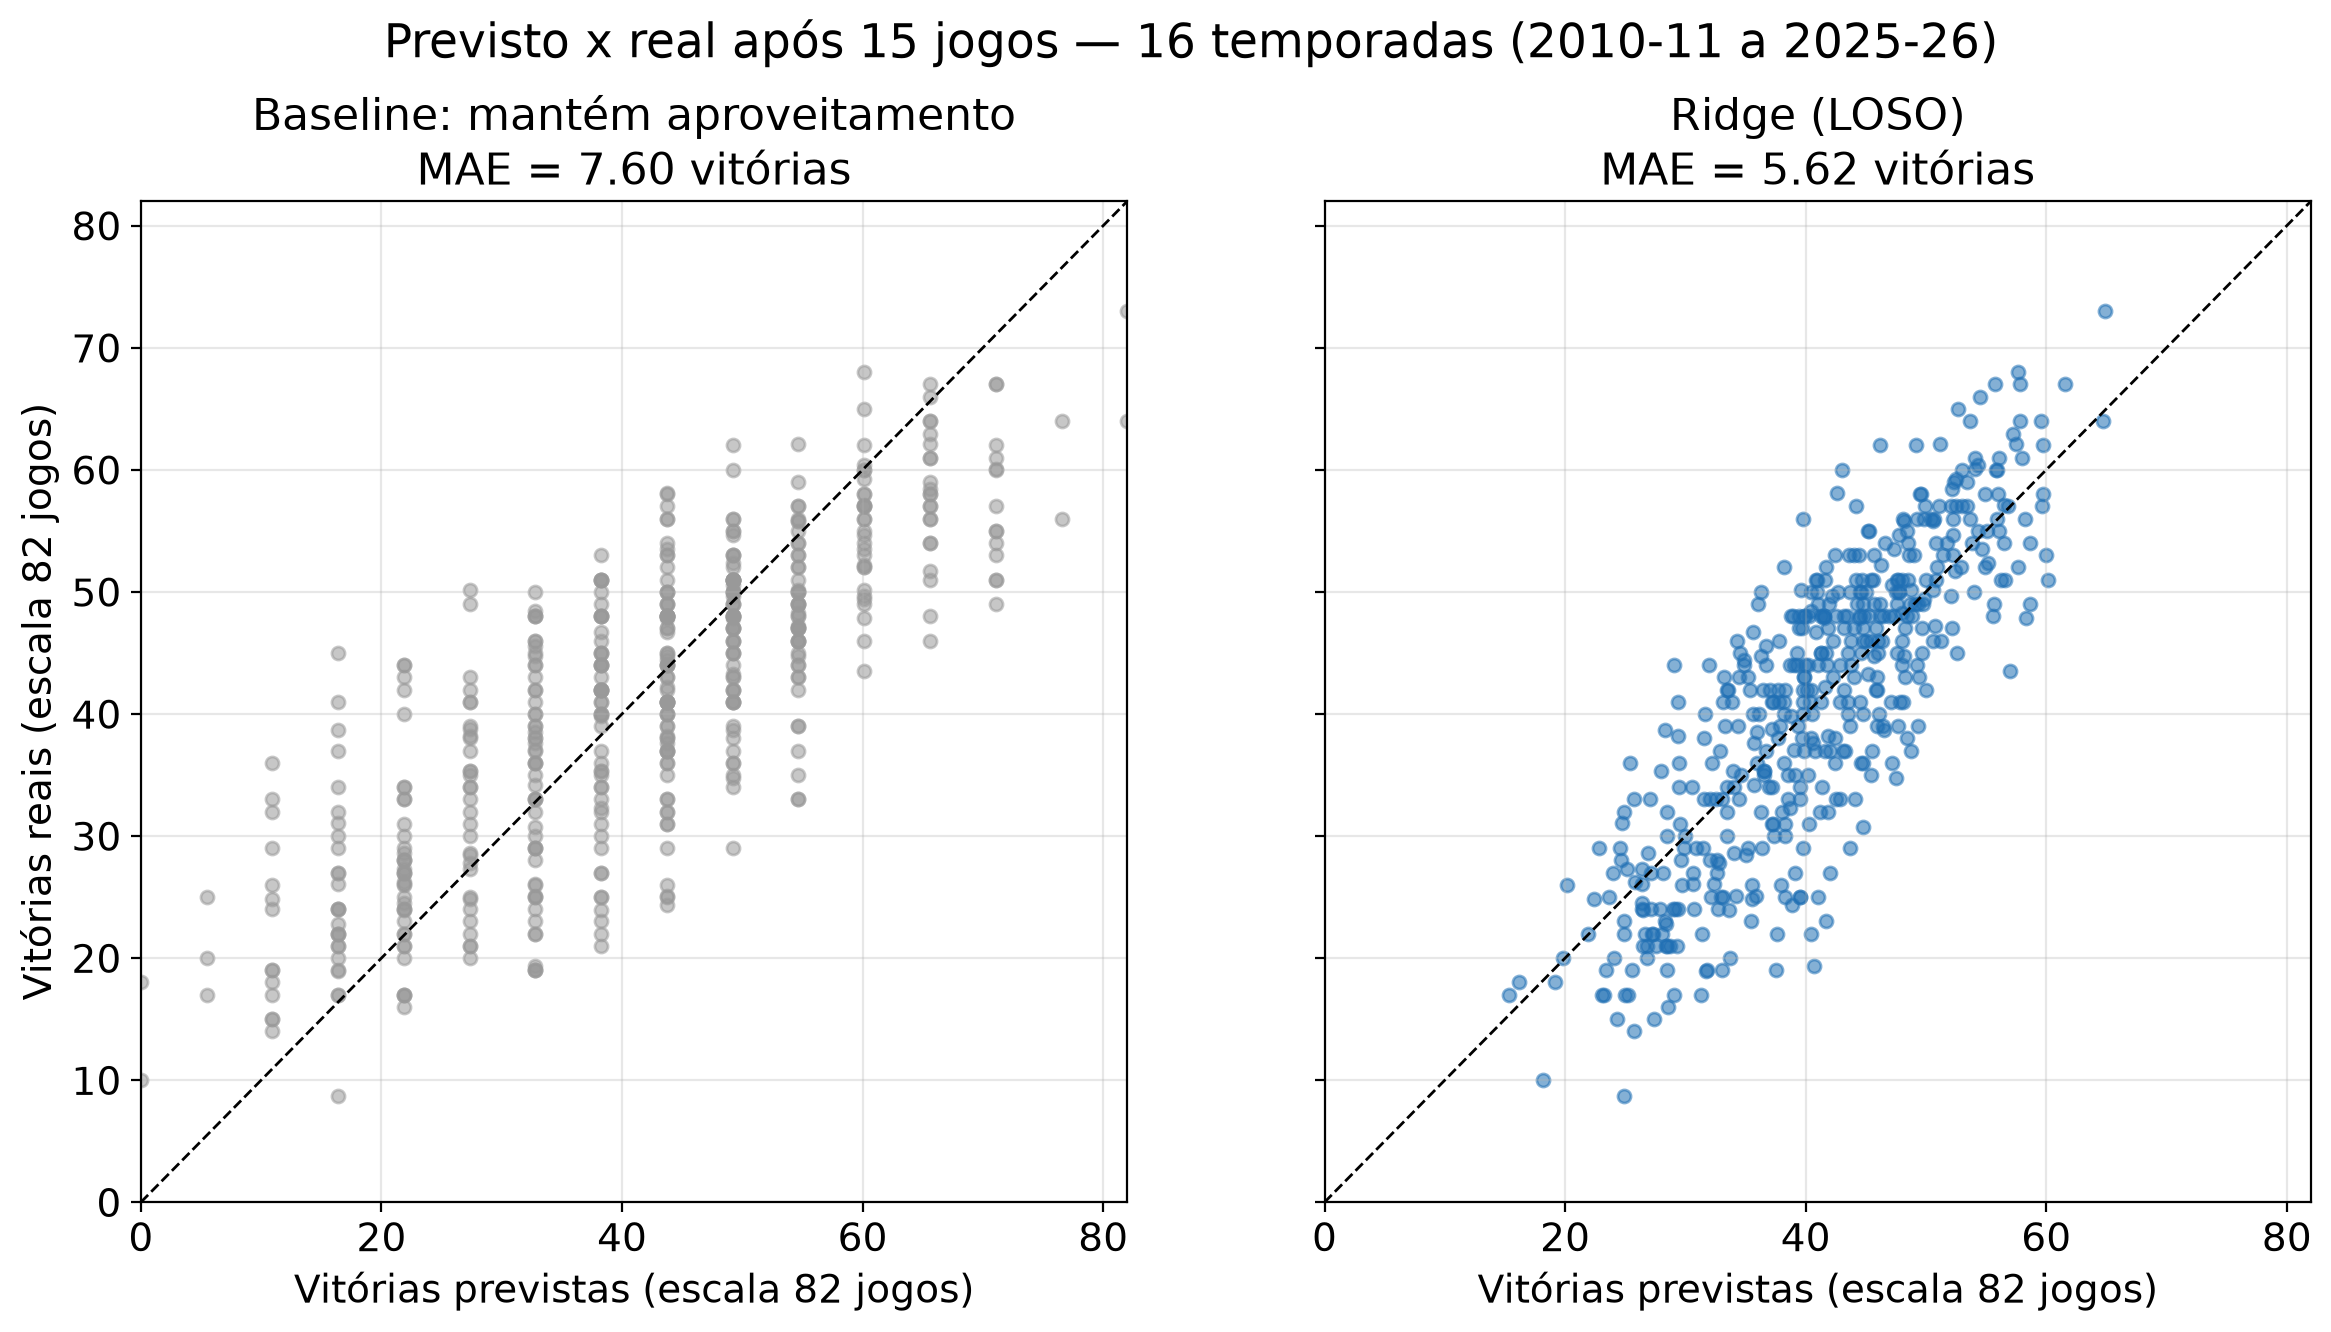

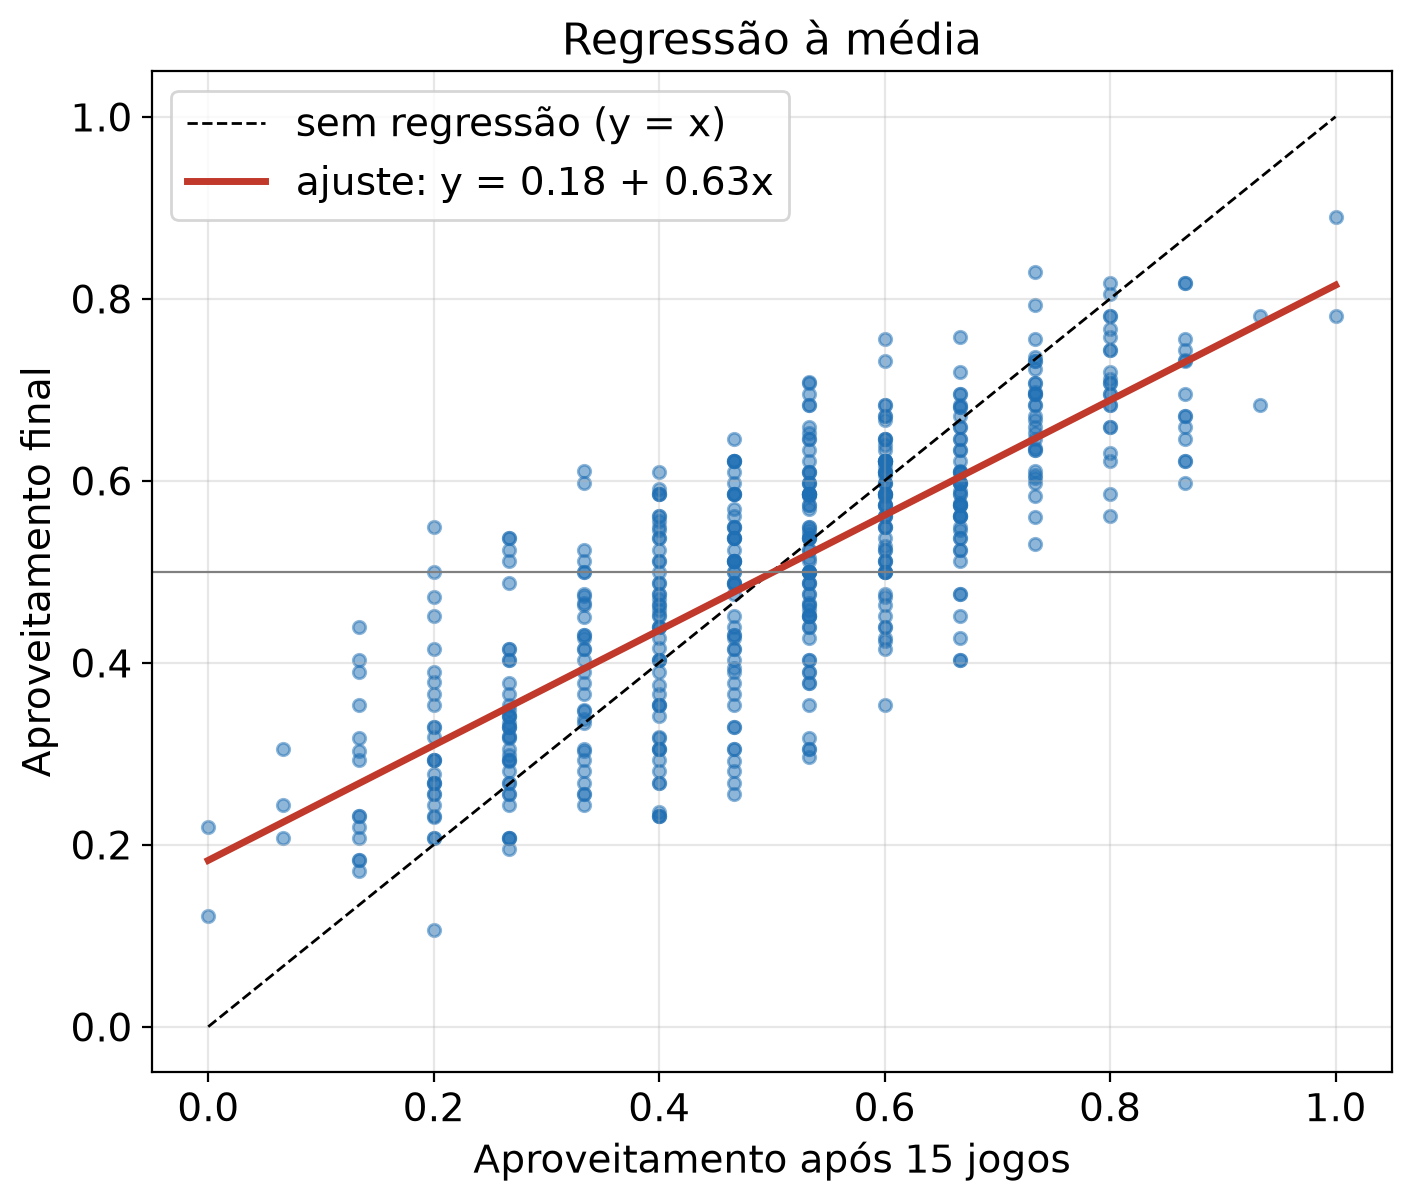

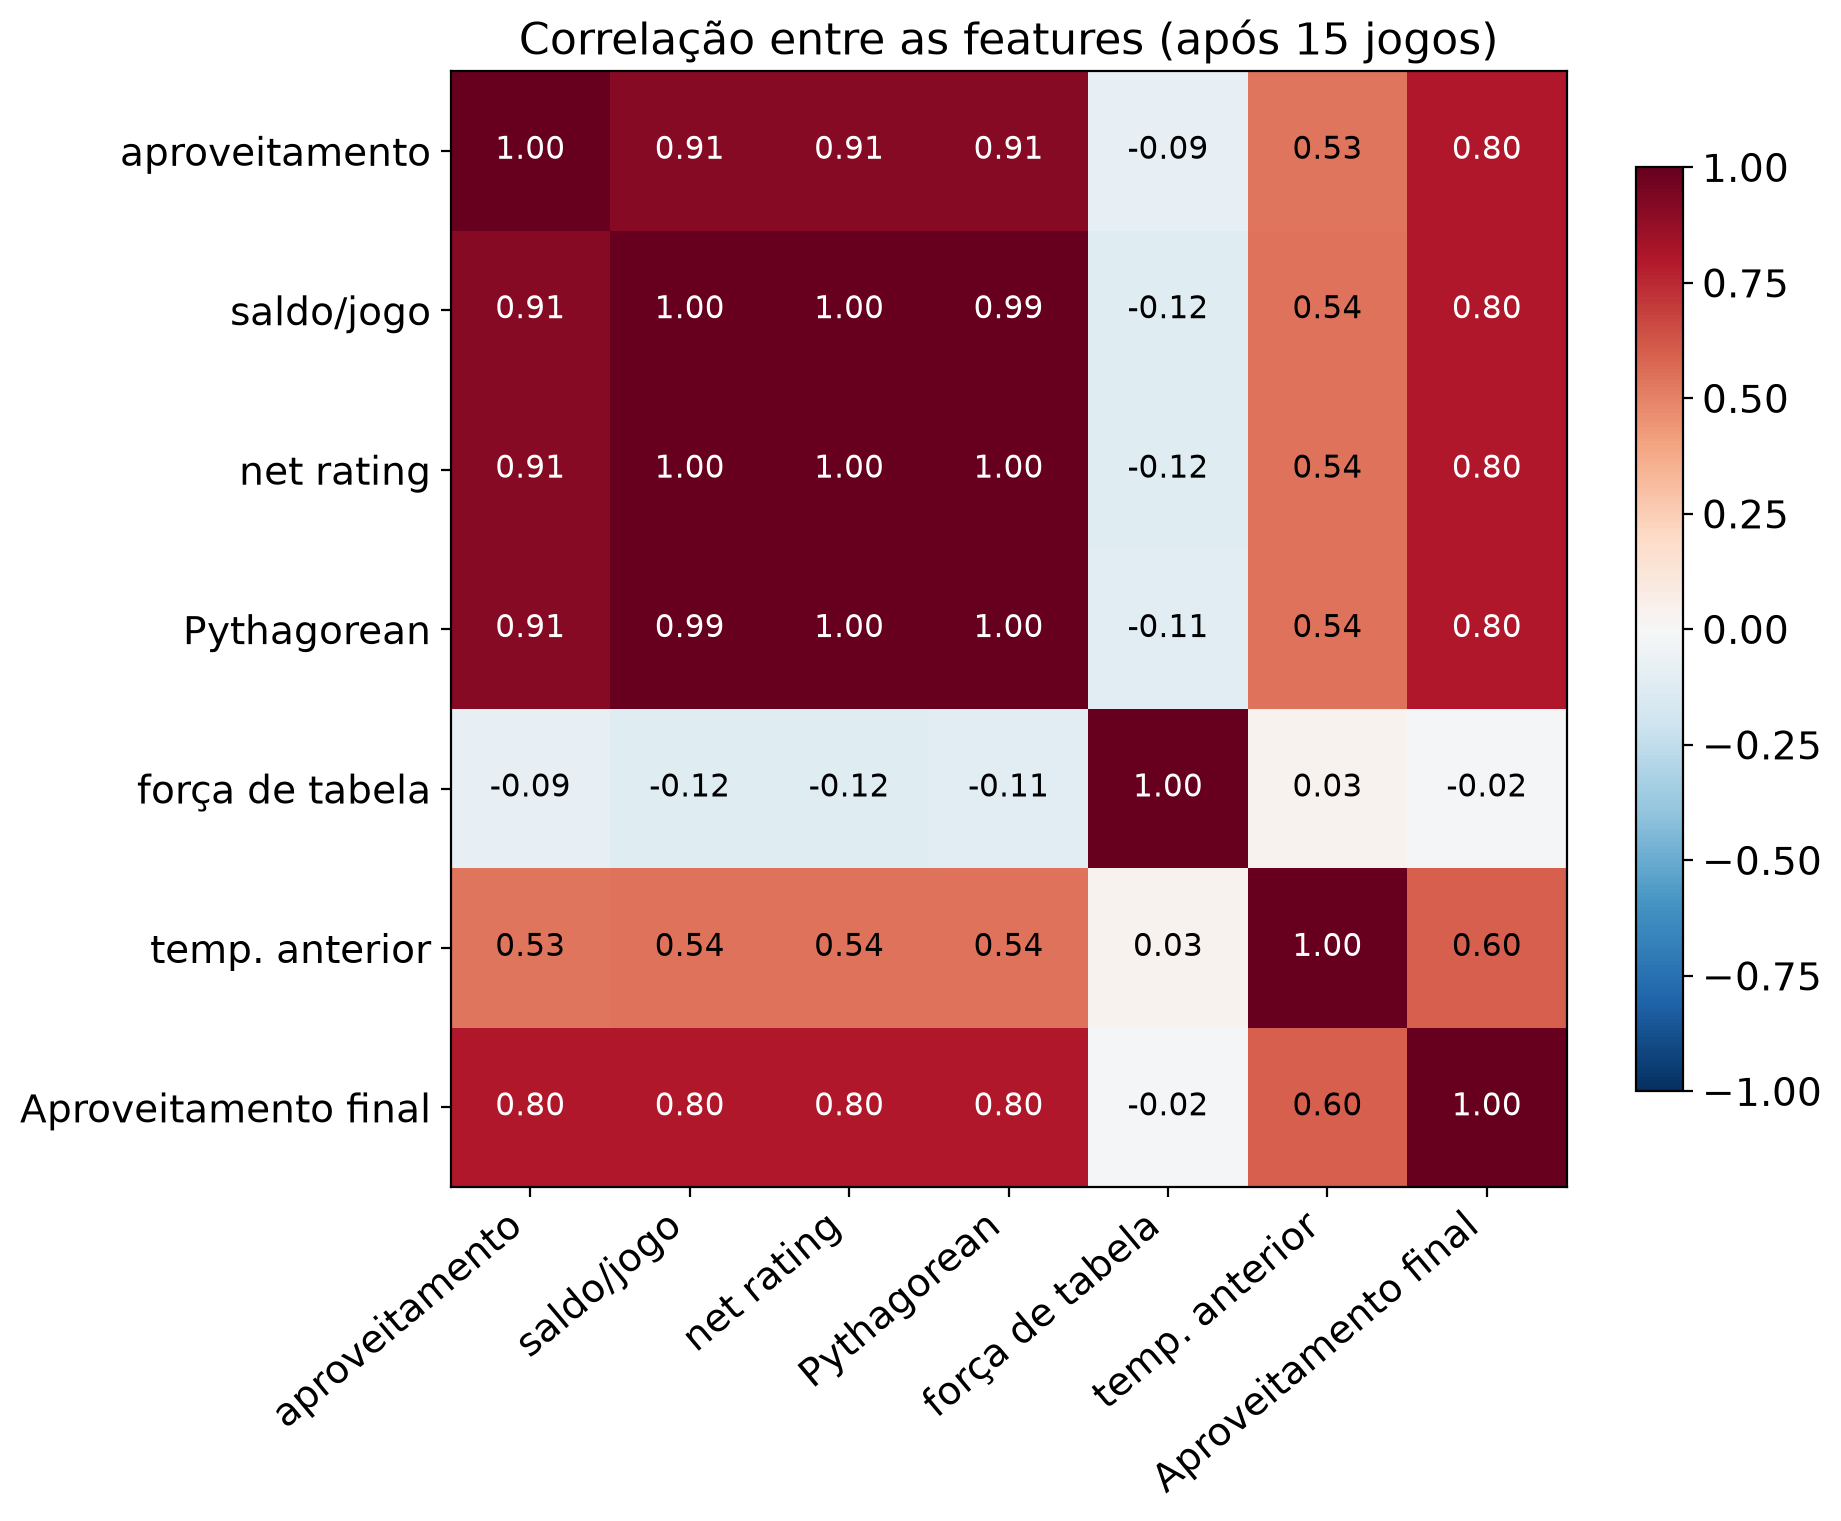

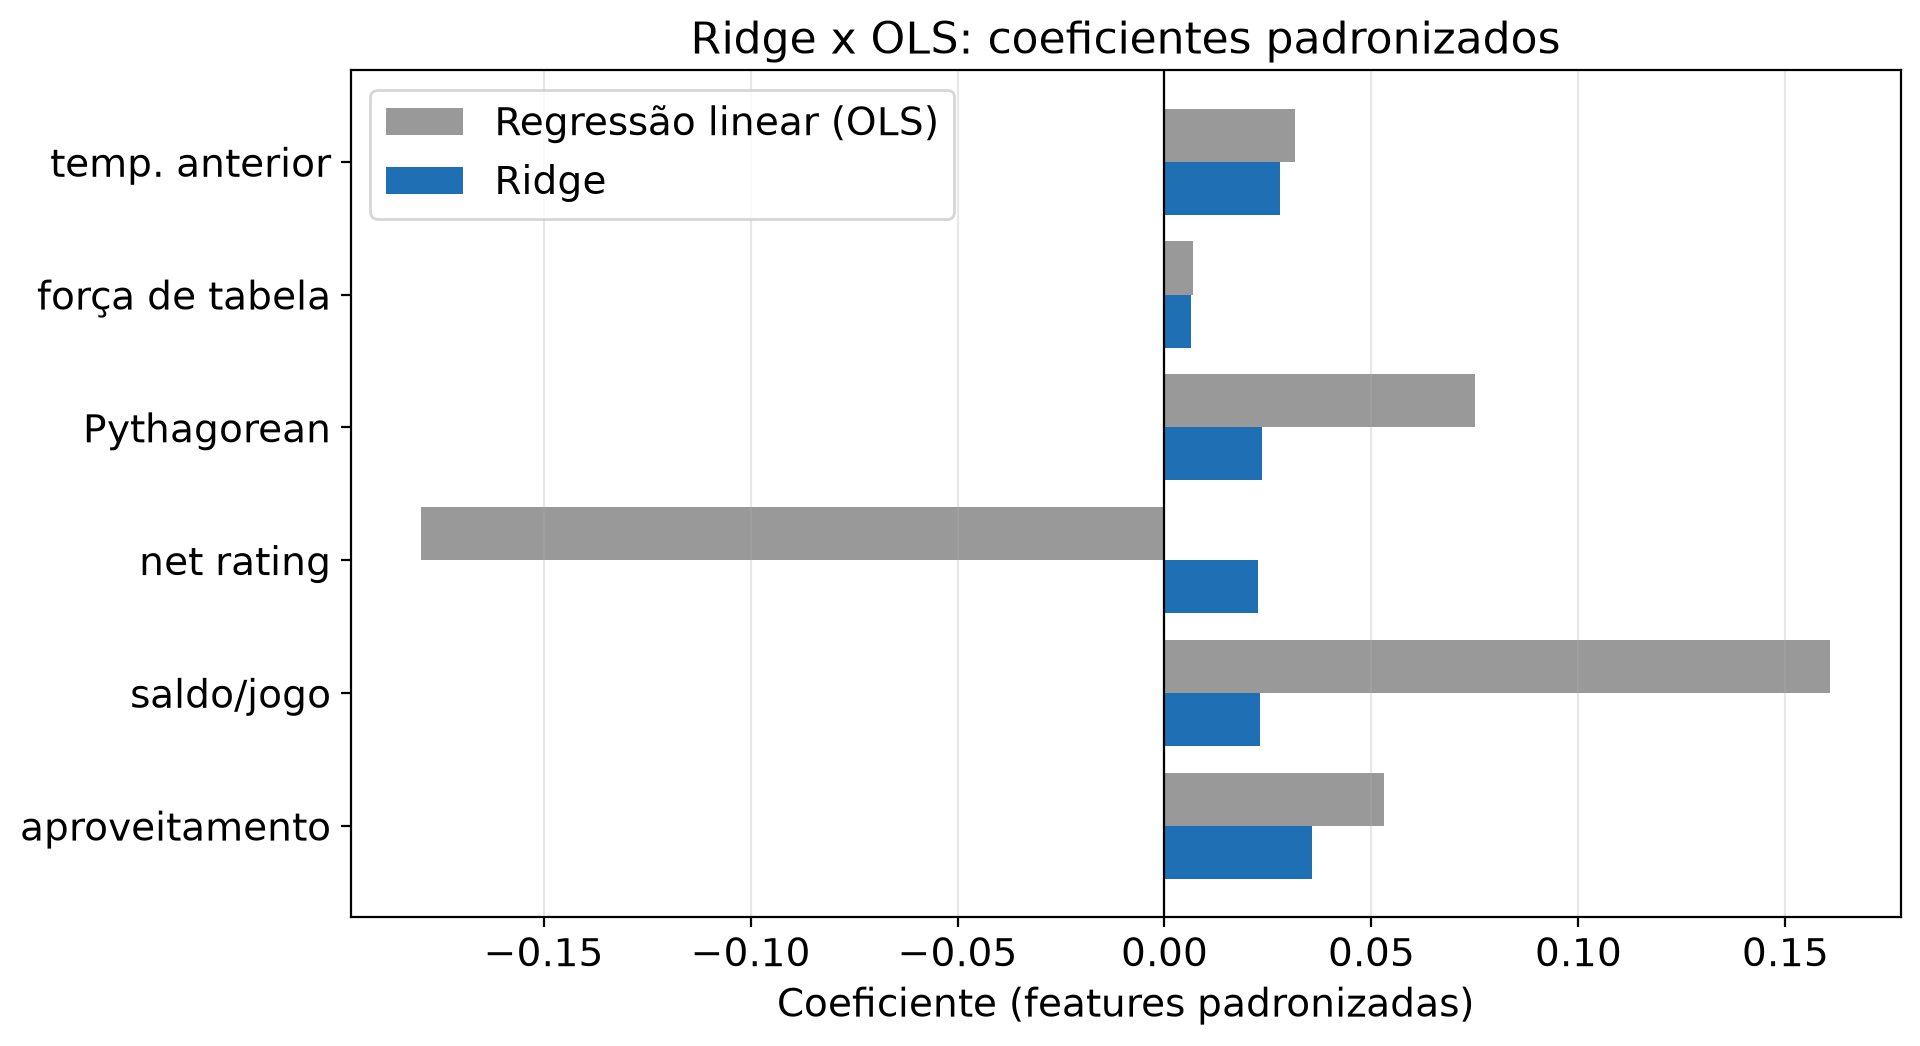

In [6]:
display(Image(ROOT / "figures/previsto_vs_real.png", width=1000))
display(Image(ROOT / "figures/regressao_a_media.png", width=550))
display(Image(ROOT / "figures/correlacao_features.png", width=600))
display(Image(ROOT / "figures/coeficientes_ridge.png", width=650))

**Leitura dos resultados.** Todos os modelos treinados reduzem o erro em ~2 vitórias em relação a manter o aproveitamento
atual. Entre os modelos treinados, as diferenças ficam abaixo de 1 erro-padrão entre temporadas.

**O encolhimento.** A inclinação de "aproveitamento final ~ aproveitamento após 15 jogos" é ~0,63: um time 12-3 (0,800)
termina, em média, perto de 0,69. A regressão já aprende essa regressão à média, com intercepto em 0,500. A penalidade
L2 do Ridge também encolhe os coeficientes e **divide o peso entre features quase colineares** (saldo, net rating e
Pythagorean têm correlação > 0,99): no OLS elas recebem coeficientes enormes e de sinais opostos, enquanto no Ridge
recebem pesos parecidos e estáveis.

### Análise complementar — sensibilidade ao número de jogos (`src/sensibilidade.py`)

Quanto vale cada jogo a mais? Reconstruímos as features com N = 5, 10, …, 41 jogos e avaliamos o baseline e o Ridge
com o mesmo protocolo LOSO. *(Esta célula leva alguns minutos.)*

N= 5  baseline MAE=13.30  Ridge MAE=7.18


N=10  baseline MAE=9.09  Ridge MAE=6.25


N=15  baseline MAE=7.60  Ridge MAE=5.62


N=20  baseline MAE=6.64  Ridge MAE=5.34


N=25  baseline MAE=6.15  Ridge MAE=4.94


N=30  baseline MAE=5.31  Ridge MAE=4.61


N=41  baseline MAE=3.94  Ridge MAE=3.60


modelo,Baseline: aproveitamento atual,Ridge
N,,
5,13.30,7.18
10,9.09,6.25
15,7.60,5.62
20,6.64,5.34
25,6.15,4.94
30,5.31,4.61
41,3.94,3.60


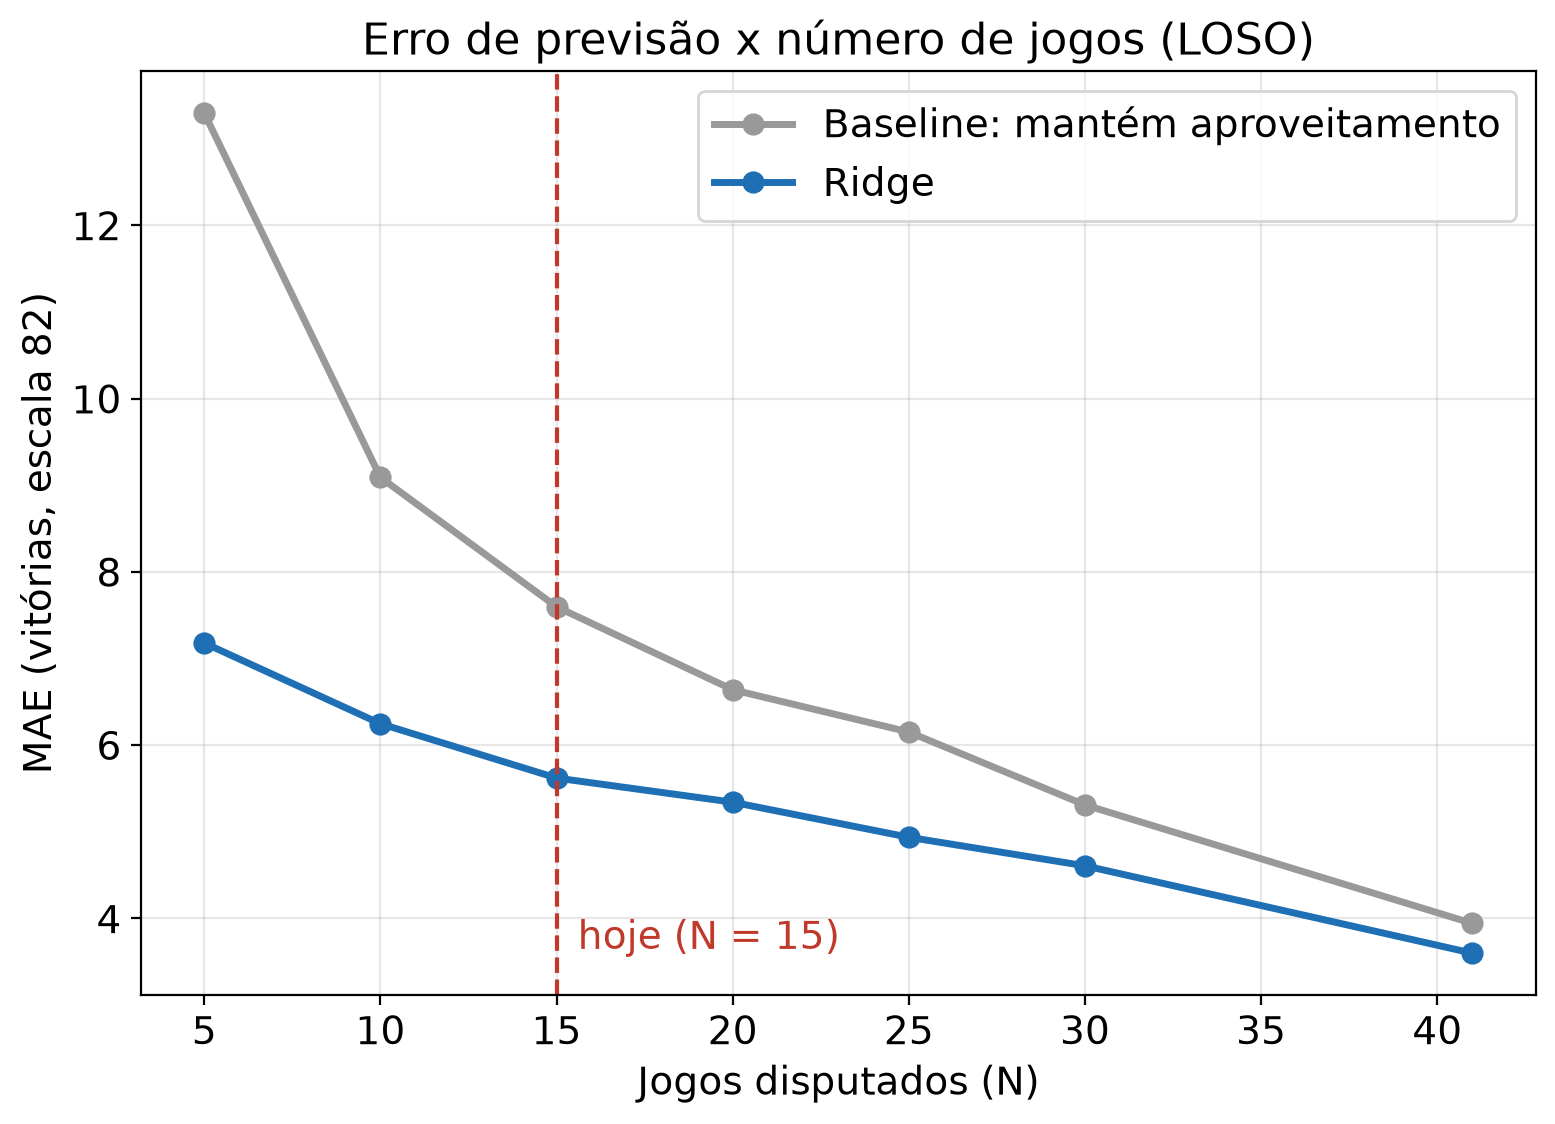

In [7]:
import sensibilidade
sensibilidade.main()
display(pd.read_csv(ROOT / "results/sensibilidade_n.csv").pivot(index="N", columns="modelo", values="MAE").round(2))
display(Image(ROOT / "figures/sensibilidade_n.png", width=650))

O ganho do modelo é maior justamente quando há pouca informação: com 5 jogos, o Ridge erra ~7 vitórias e o baseline ~13.
Com meia temporada (41 jogos), os dois convergem, porque o aproveitamento já é pouco ruidoso.

## Fase 4 — Simulação Monte Carlo (`src/simulacao.py`)

1. **Rating** de cada time = aproveitamento final previsto pelo Ridge. No treino do modelo de jogo usamos as previsões
   LOSO (fora da amostra).
2. **Modelo de jogo:** regressão logística `logit P(vitória) = b_diff·(rating − rating_adv) + b_casa·mando`
   (mando = ±1), treinada nos jogos históricos disputados depois do N-ésimo jogo de ambos os times.
3. **Incerteza do rating:** em cada simulação, cada rating recebe um ruído N(0, σ), com σ estimado dos resíduos LOSO
   descontando a variância binomial dos jogos restantes.
4. **10.000 simulações** dos jogos restantes, somando às vitórias atuais, mais os 2 jogos da Cup ainda não definidos.
5. **Desempate aleatório** (limitação).

Antes de projetar 2026-27, fazemos um **backtest totalmente fora da amostra**: cada temporada histórica é simulada a
partir da data em que o último time completou N jogos (a mesma situação de hoje), com o rating LOSO e o modelo de
jogo/σ reajustados **sem** a temporada testada. Depois verificamos se o intervalo de 80% realmente contém ~80% dos
resultados reais e se as probabilidades estão calibradas.

In [8]:
import simulacao
simulacao.main()

Modelo de jogo (30790 linhas time-jogo): b_diff = 4.353, b_casa = 0.320 -> P(vitória em casa, times iguais) = 0.579
  acurácia = 0.643, log-loss = 0.6291; sigma do rating = 0.085


Backtest 16 temporadas (corte na data em que o último time completa 15 jogos; times com 15-22 jogos no corte):
  Brier (3 classes) = 0.421 vs 0.658 da referência constante; cobertura do IC80 de vitórias = 81.0%


2026-27: 952 jogos restantes no calendário; jogos extras (Cup, a definir) por time: [2]


 CONF TEAM  V_atual  D_atual  vitorias_esperadas  IC80  P_top6  P_playin  P_fora
Leste  BOS       11        6                55.8 48-63    97.2       2.8     0.0
Leste  DET       10        6                53.6 46-61    94.0       5.9     0.1
Leste  PHI       14        3                52.4 44-60    90.5       9.4     0.1
Leste  NYK       11        6                50.9 43-59    86.5      13.2     0.2
Leste  ATL       11        6                46.5 38-55    66.6      32.0     1.3
Leste  CLE        9        8                45.7 37-54    61.5      36.5     1.9
Leste  MIA       10        6                45.6 37-54    60.8      37.1     2.1
Leste  TOR        6       10                38.1 30-47    18.9      65.4    15.7
Leste  ORL        7        9                38.0 29-47    18.4      65.3    16.4
Leste  IND        5       12                30.7 23-39     2.6      41.3    56.1
Leste  CHI        4       12                28.2 20-36     1.2      27.5    71.3
Leste  CHA        4       11

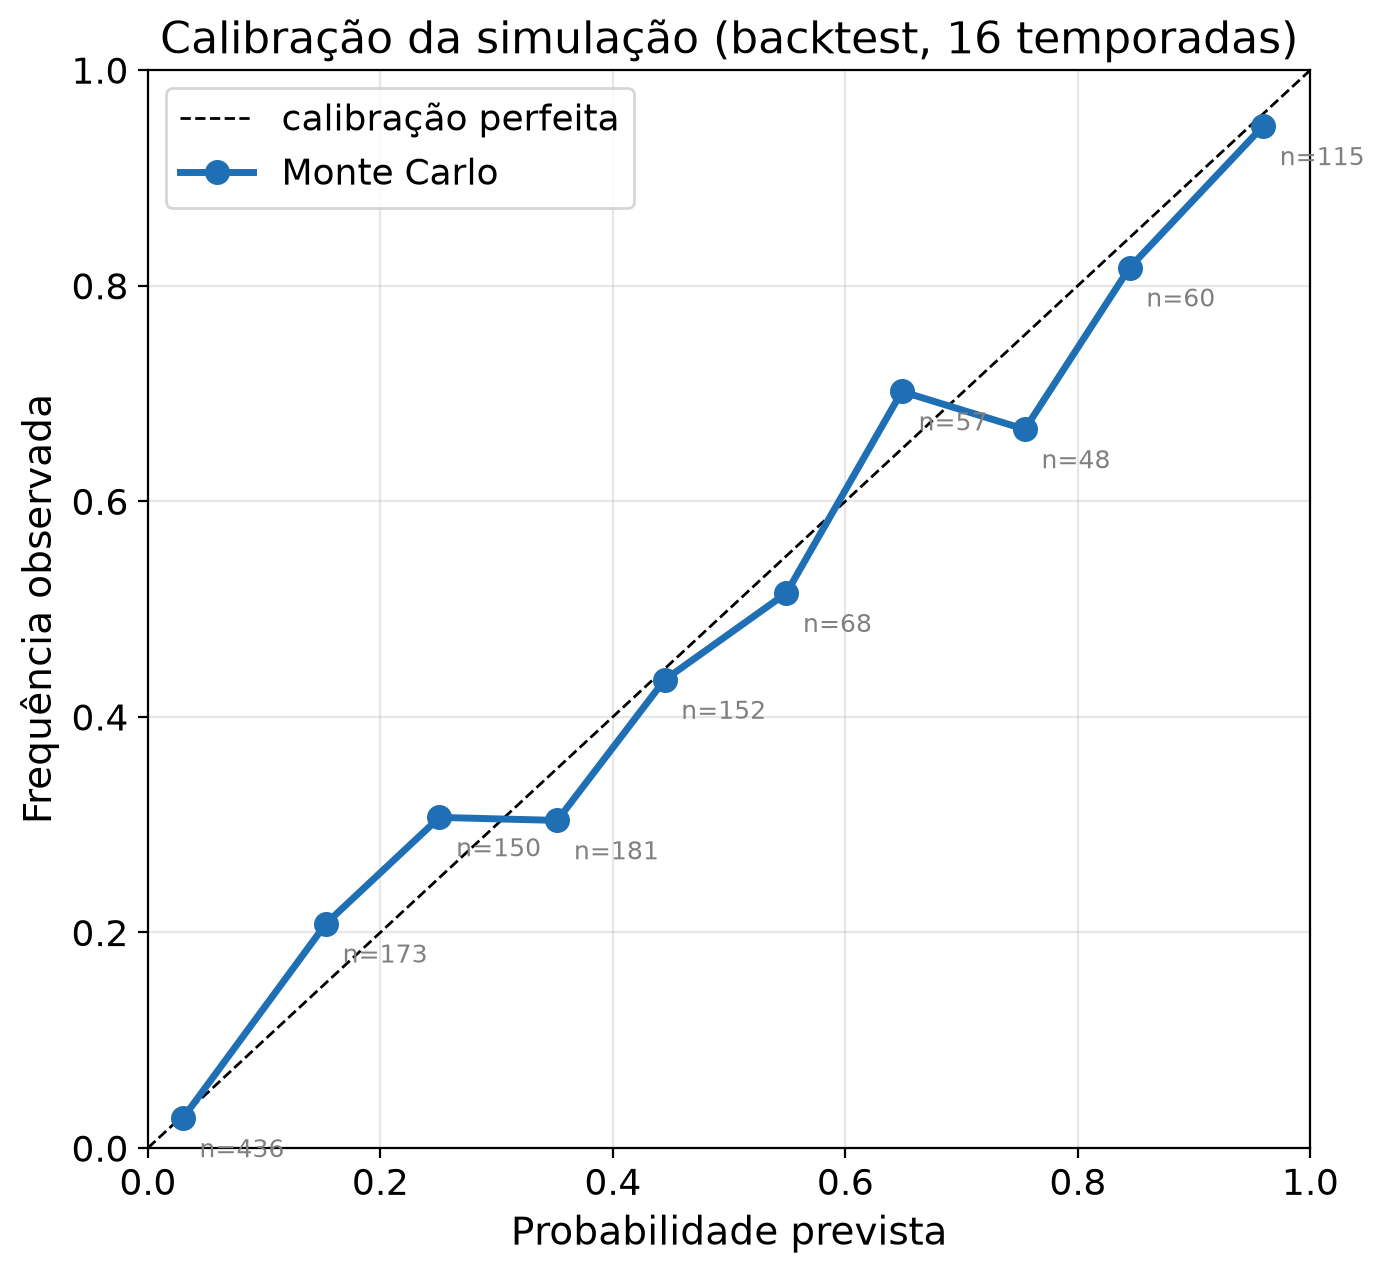

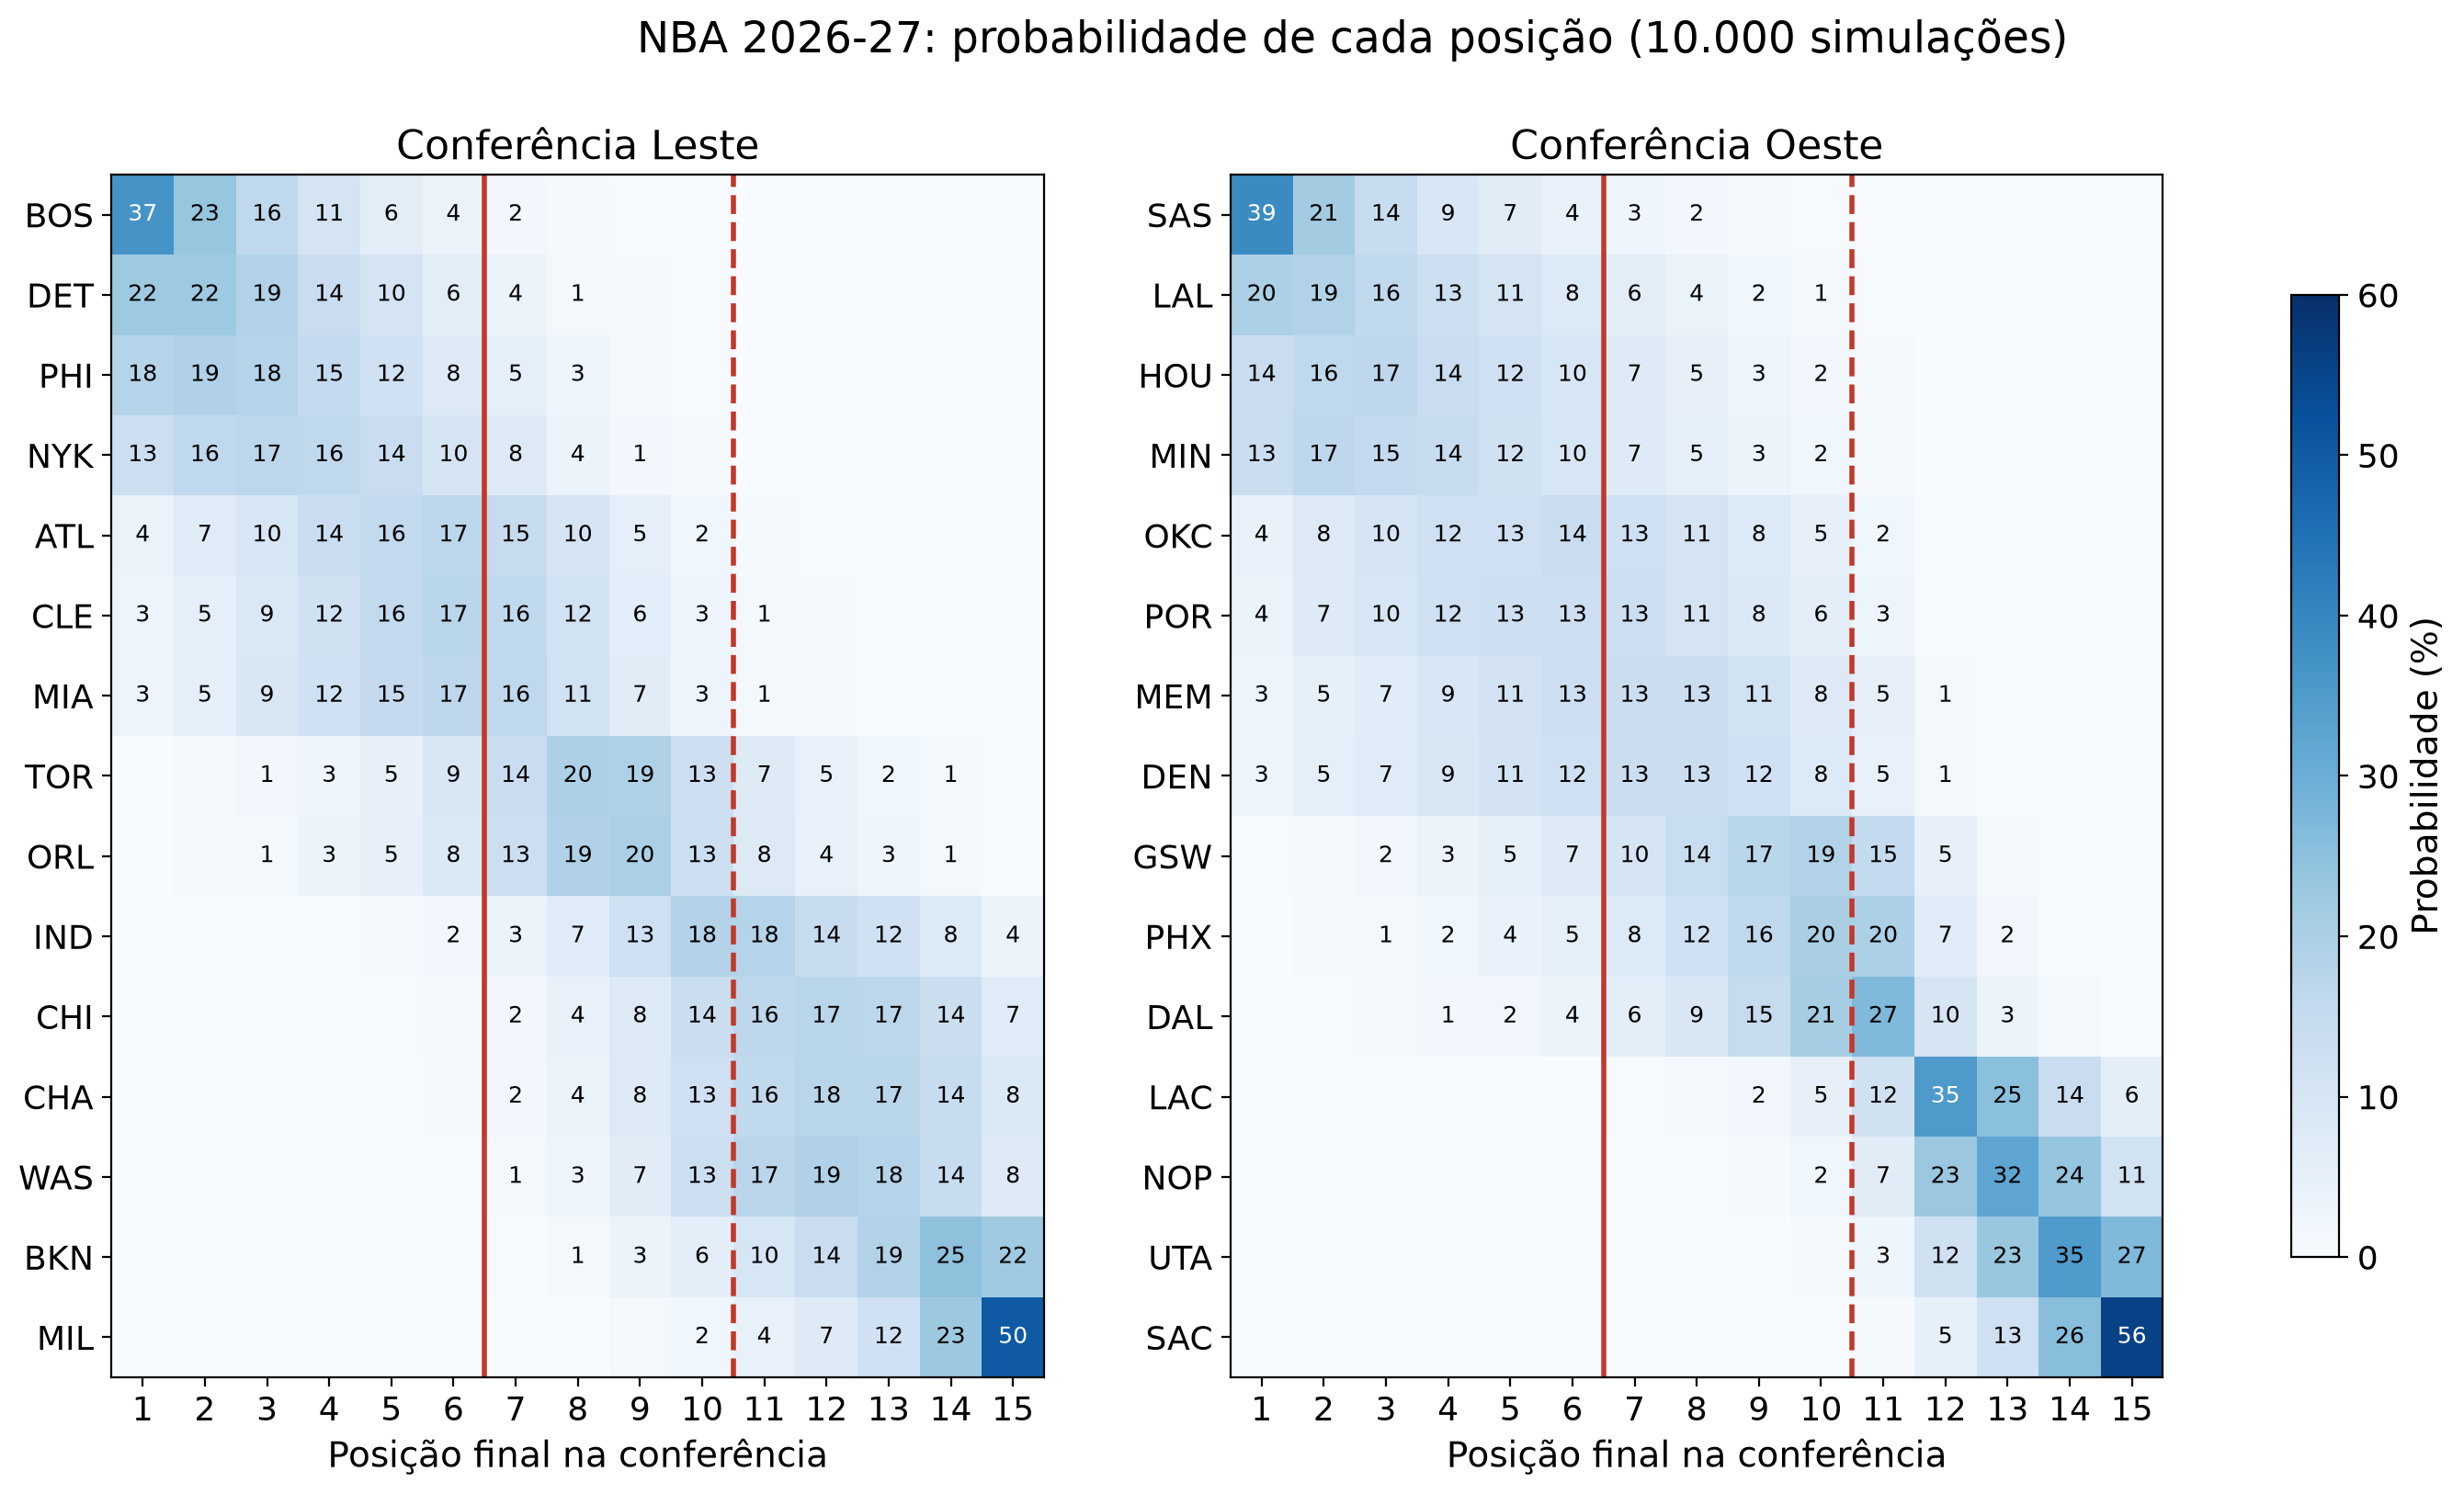

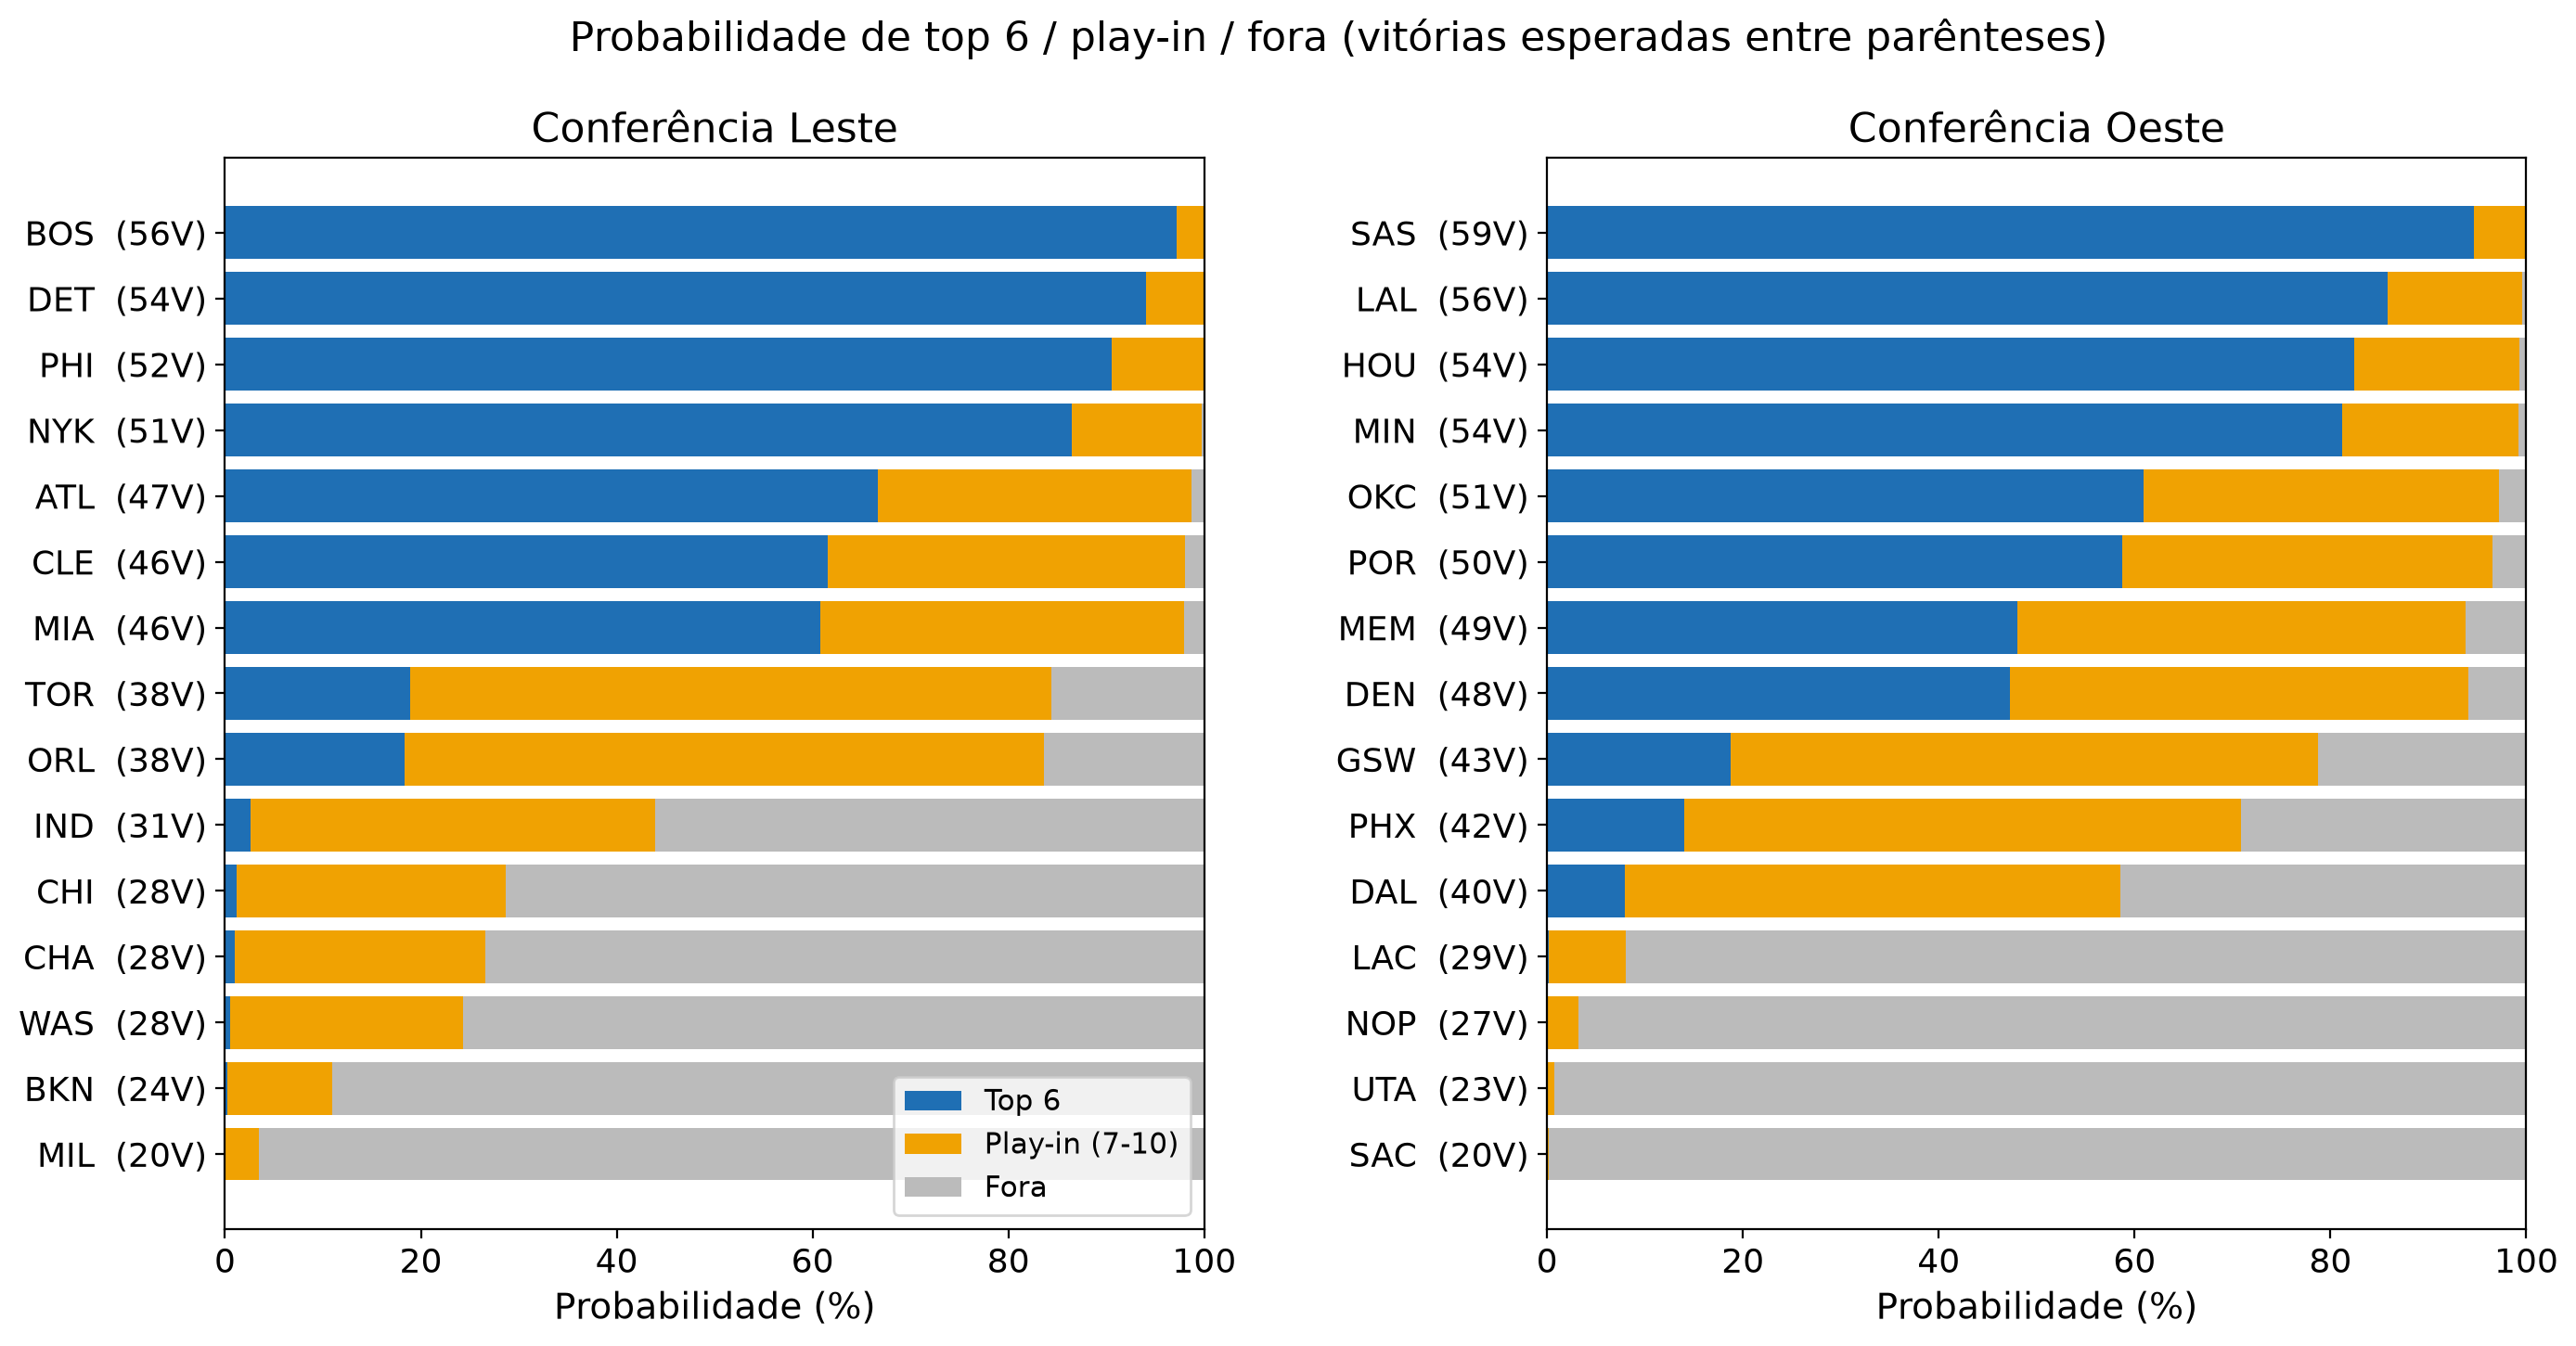

In [9]:
display(Image(ROOT / "figures/calibracao_simulacao.png", width=550))
display(Image(ROOT / "figures/heatmap_posicoes.png", width=1100))
display(Image(ROOT / "figures/probabilidades_top6_playin.png", width=1100))

A curva de calibração fica próxima da diagonal: quando a simulação diz "30% de chance", o evento acontece ~30% das
vezes. Por isso dá para levar a sério as probabilidades de top 6 / play-in / fora.

> As figuras em inglês (para o artigo/slides em EN) são geradas em `figures/en/`.

## Fase 4b — Versões com 0, 5, 10 e 15 jogos (`src/versoes.py`)

Para ver quanto cada bloco de jogos acrescenta, refazemos o pipeline inteiro em quatro datas de 2026-27: a véspera da
estreia (V0, só a temporada anterior) e os dias em que o último time completou 5, 10 e 15 jogos. Em cada versão o Ridge,
o modelo de jogo, o σ e o backtest são reajustados com as features daquela data, e a simulação parte da campanha daquele
dia. Jogos disputados depois da data de corte entram como "ainda não jogados". A V15 é igual à simulação da Fase 4.
*(Esta célula leva cerca de 1 minuto.)*

V0  corte 2026-10-19 (0-0 jogos): MAE LOSO 8.54 -> 8.15; sigma 0.111; Brier 0.533; cobertura 87.3%; MAE backtest 7.84


V5  corte 2026-11-02 (5-8 jogos): MAE LOSO 13.30 -> 7.18; sigma 0.101; Brier 0.488; cobertura 80.6%; MAE backtest 6.95


V10 corte 2026-11-11 (10-13 jogos): MAE LOSO 9.09 -> 6.25; sigma 0.092; Brier 0.444; cobertura 79.4%; MAE backtest 5.97


V15 corte 2026-11-22 (15-18 jogos): MAE LOSO 7.60 -> 5.62; sigma 0.085; Brier 0.421; cobertura 81.0%; MAE backtest 5.32



Vitórias esperadas por versão:
              V0    V5   V10   V15
CONF  TEAM                        
Leste BOS   49.0  53.1  57.0  55.8
      DET   50.8  54.6  55.1  53.6
      PHI   43.1  48.8  50.1  52.4
      NYK   46.9  43.6  49.9  50.9
      ATL   43.6  45.4  46.2  46.5
      CLE   46.7  45.9  46.3  45.7
      MIA   42.1  35.3  37.2  45.6
      TOR   43.4  48.8  43.2  38.1
      ORL   43.1  36.3  34.1  38.0
      IND   30.2  32.2  30.7  30.7
      CHI   35.9  27.0  23.1  28.2
      CHA   42.6  37.3  29.2  27.8
      WAS   29.0  33.3  30.9  27.7
      BKN   30.3  25.2  26.3  24.0
      MIL   36.5  29.6  23.8  20.2
Oeste SAS   51.7  51.8  57.0  58.9
      LAL   46.9  52.0  54.1  55.8
      HOU   46.6  56.4  54.1  54.5
      MIN   44.6  50.0  52.7  54.3
      OKC   52.8  52.7  55.5  50.5
      POR   41.2  50.1  50.1  50.2
      DEN   47.2  44.0  46.0  48.5
      MEM   32.7  46.7  44.3  48.5
      GSW   39.1  39.8  47.3  43.2
      PHX   43.2  33.9  36.5  41.8
      DAL   33.4  39.0 

,versao,N,data_corte,jogos_no_corte,MAE_LOSO_baseline,MAE_LOSO_ridge,Spearman_LOSO_ridge,sigma,b_diff,b_casa,brier_backtest,brier_referencia,cobertura_ic80,MAE_backtest_vitorias
0,V0,0,2026-10-19,0-0,8.5446,8.1521,0.5827,0.1106,5.4046,0.3145,0.5332,0.6578,0.8729,7.8373
1,V5,5,2026-11-02,5-8,13.2955,7.1788,0.6549,0.1014,4.5232,0.3199,0.4879,0.6578,0.8062,6.9454
2,V10,10,2026-11-11,10-13,9.0911,6.2473,0.7280,0.0922,4.3373,0.3260,0.4435,0.6578,0.7938,5.9694
3,V15,15,2026-11-22,15-18,7.5969,5.6203,0.7842,0.0850,4.3535,0.3204,0.4207,0.6578,0.8104,5.3242


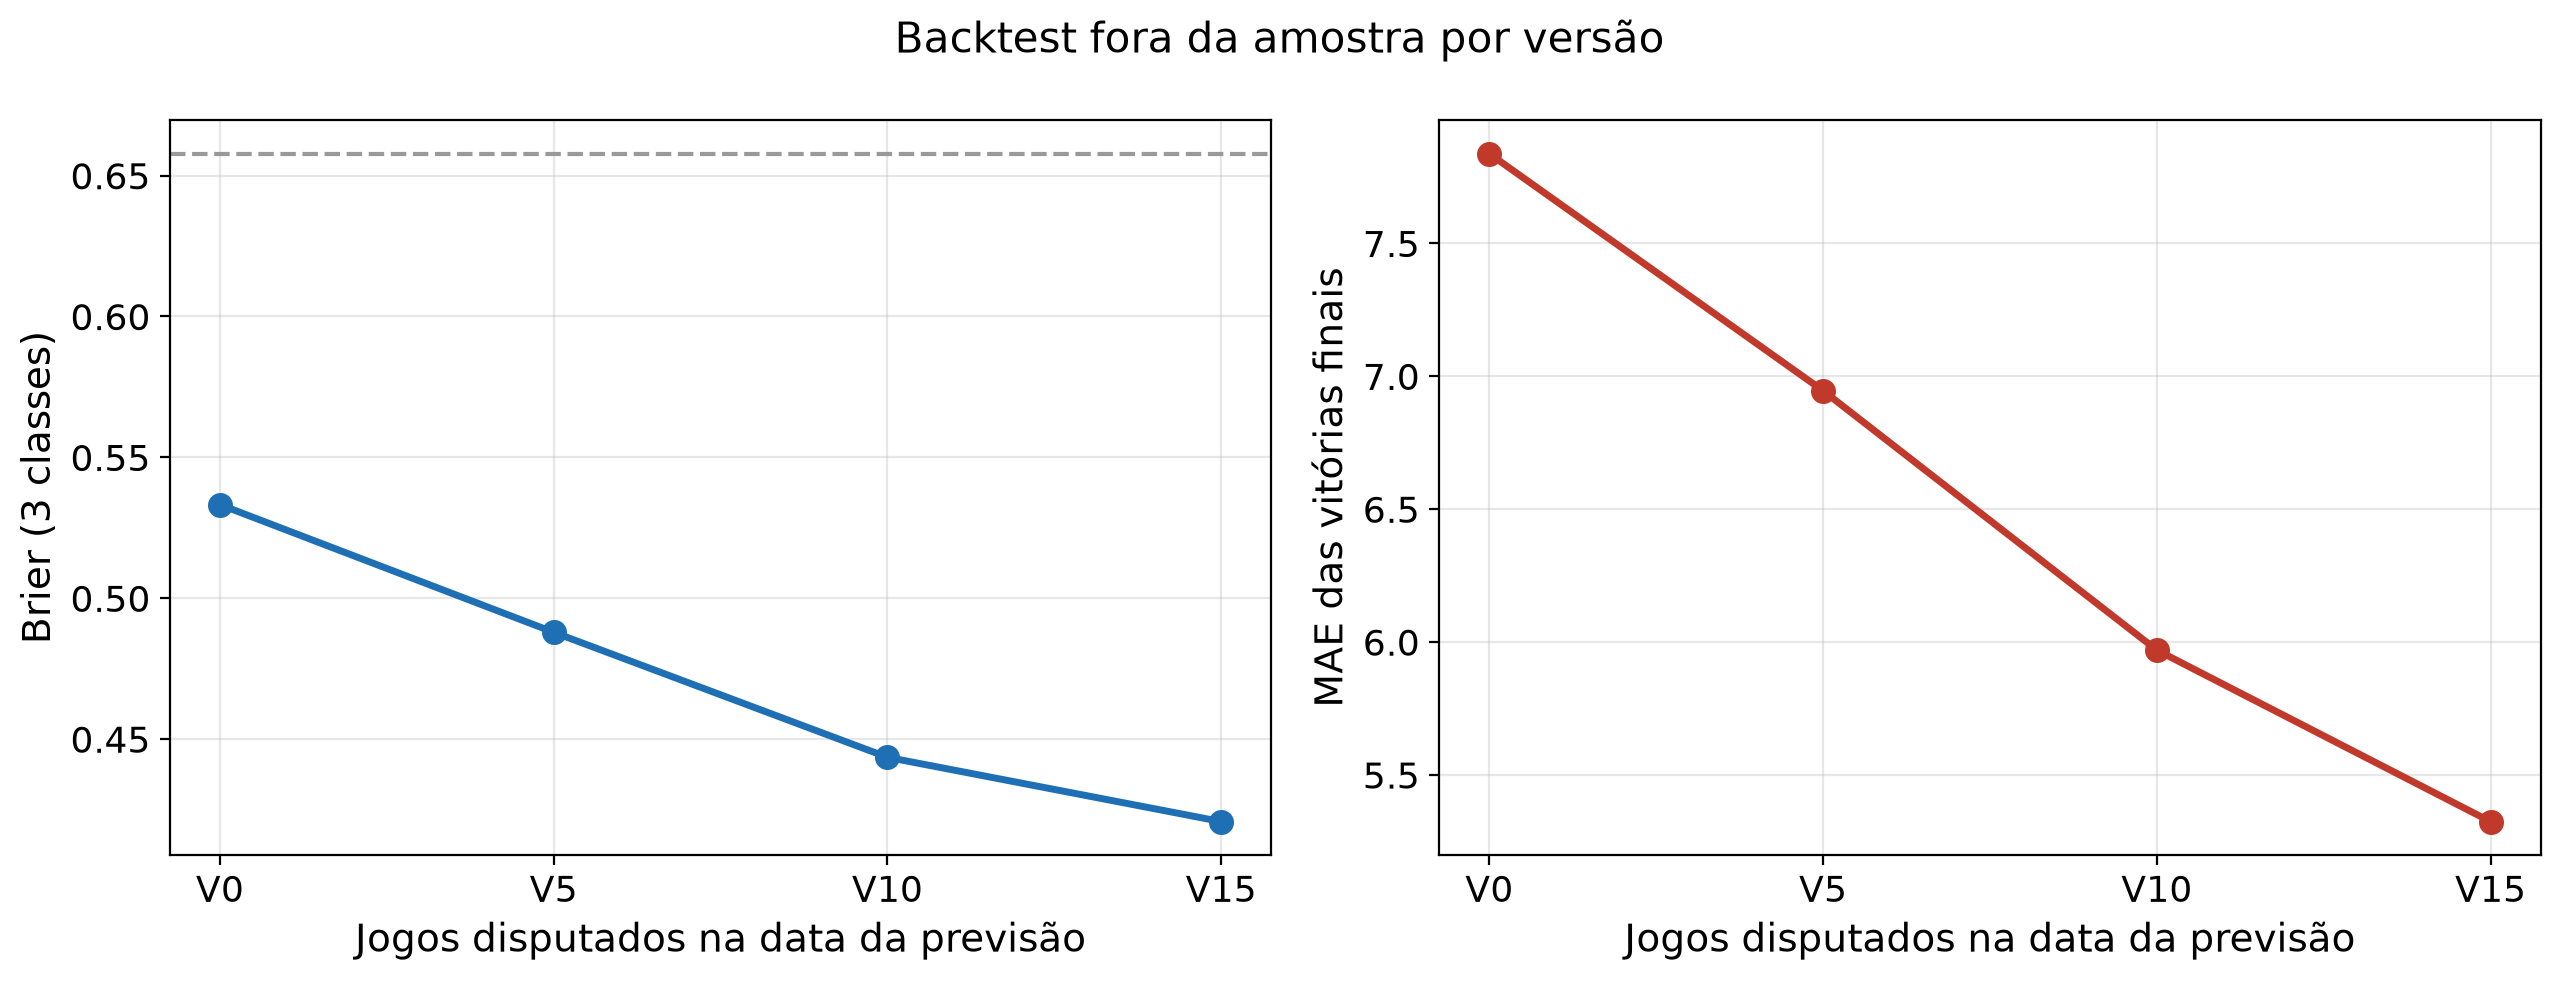

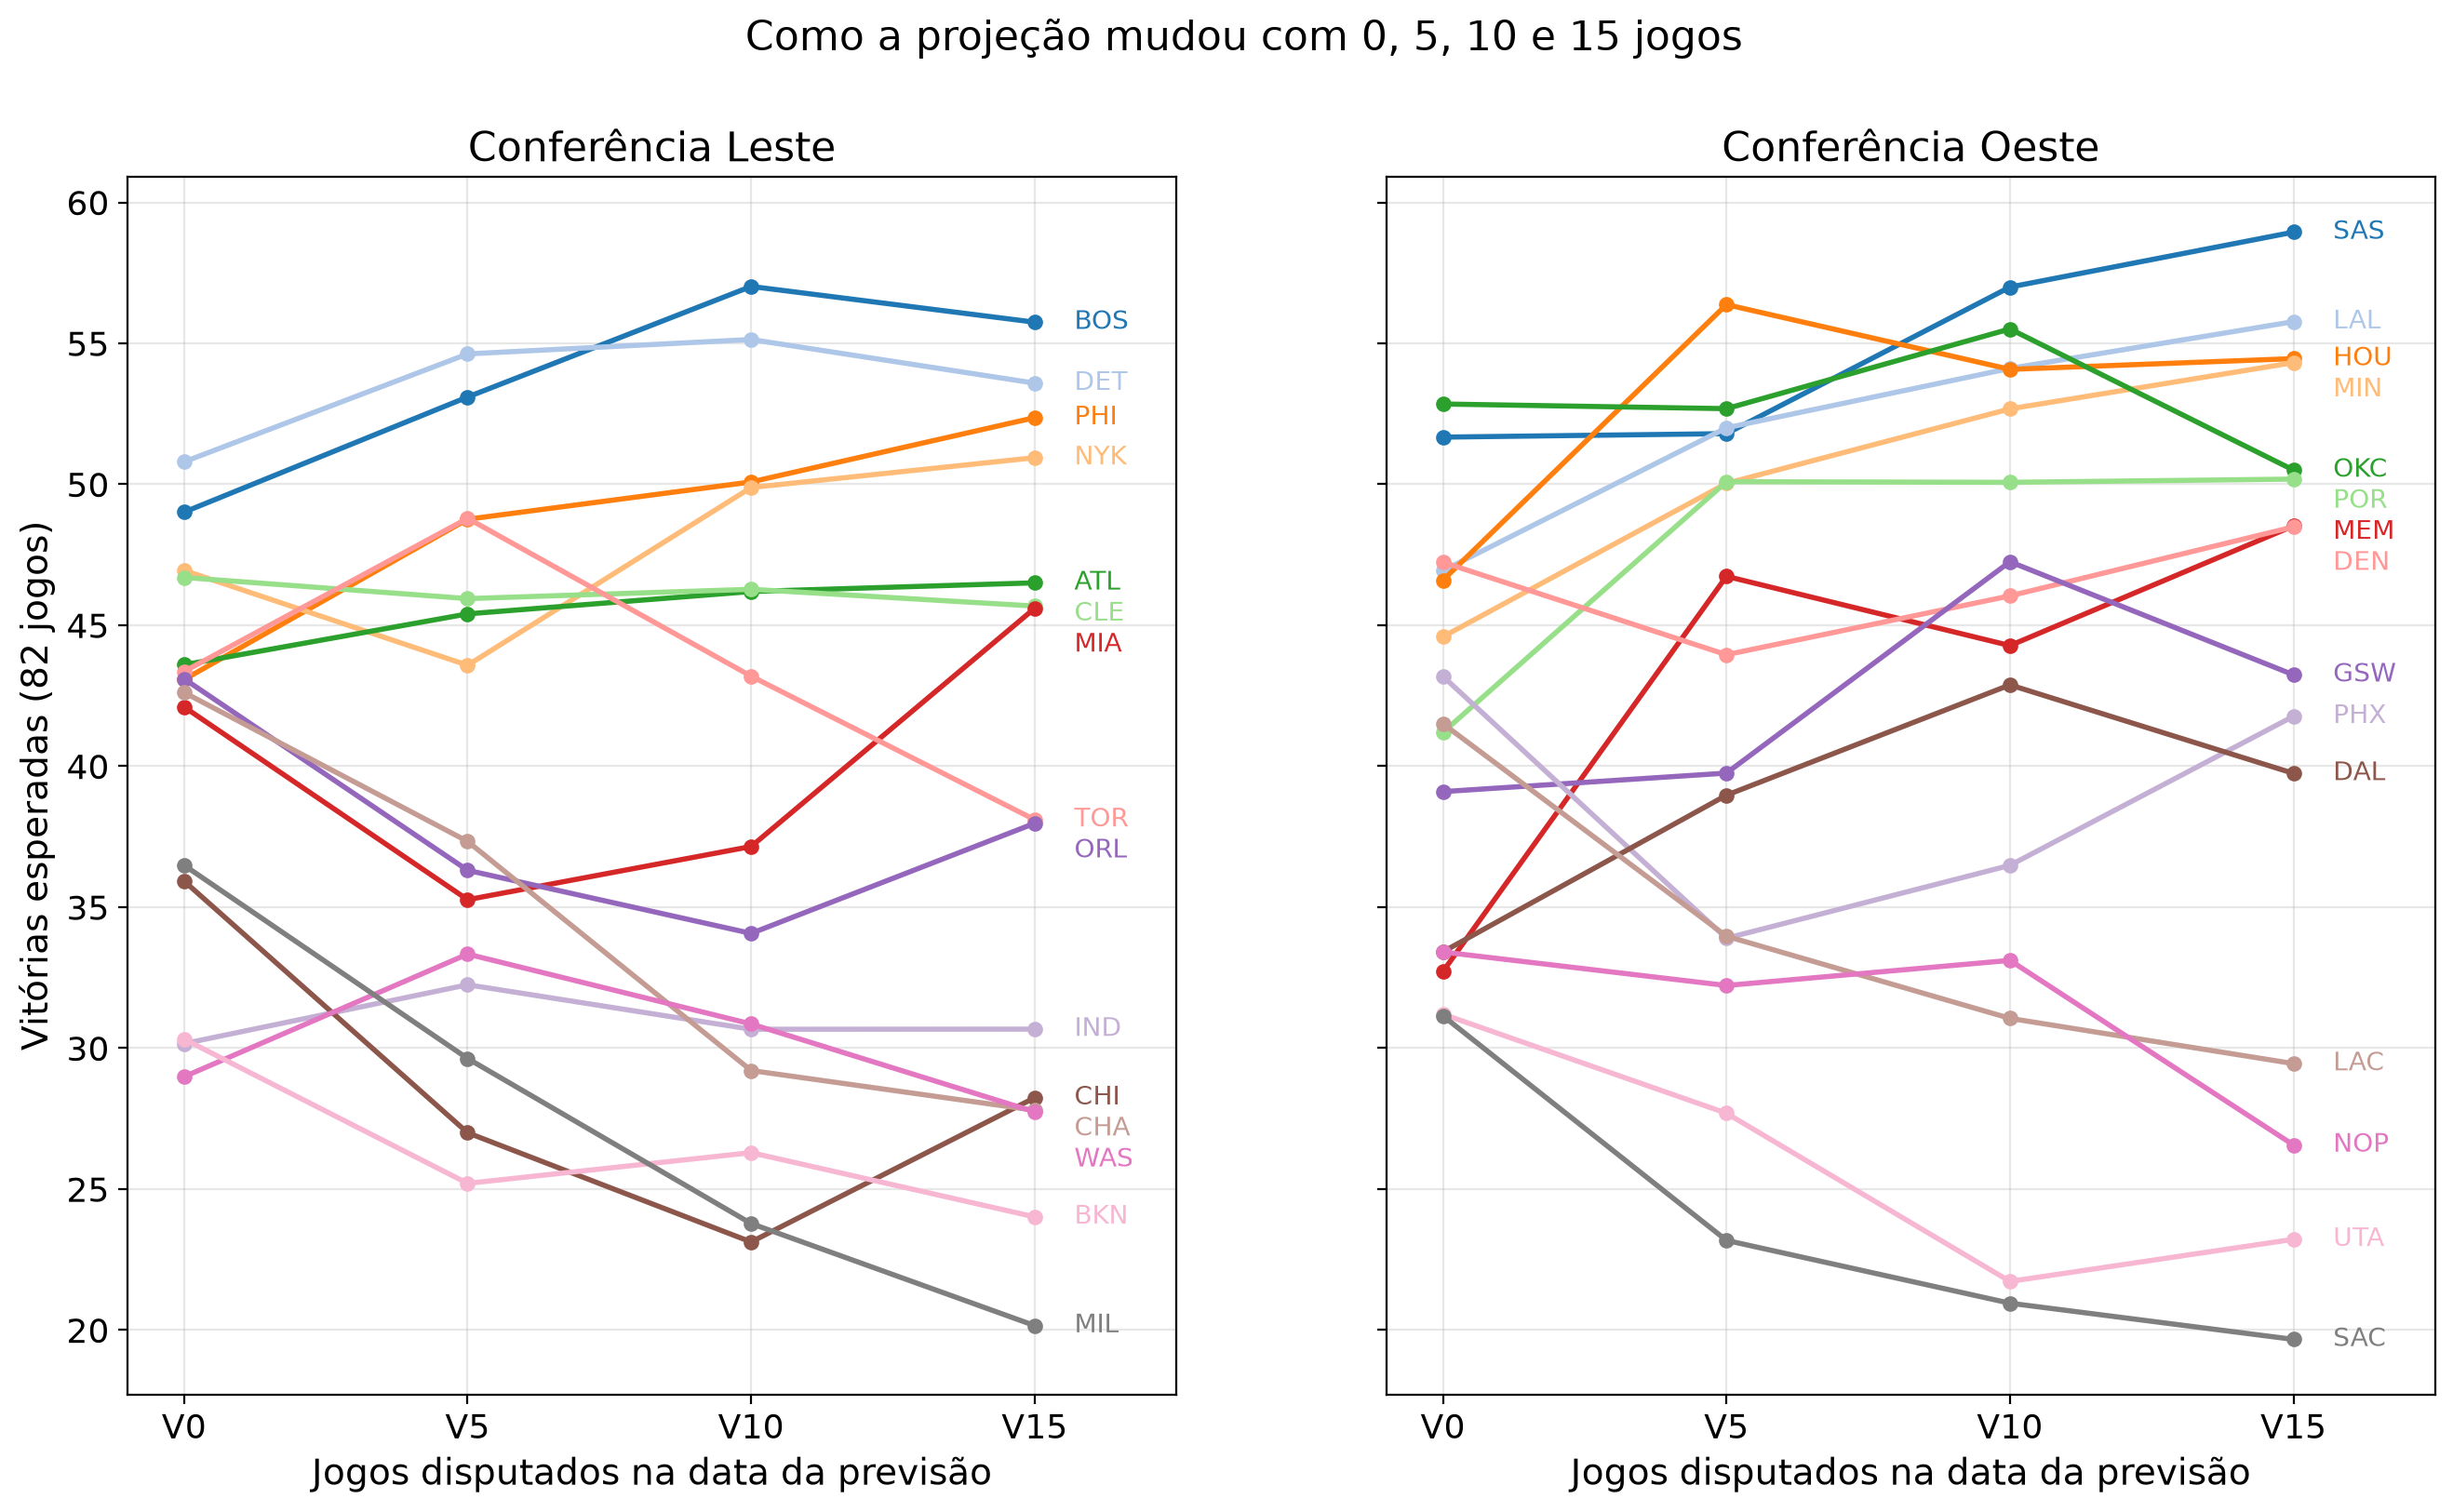

In [10]:
import versoes
versoes.main()
display(pd.read_csv(ROOT / "results/versoes_resumo.csv"))
display(Image(ROOT / "figures/versoes_backtest.png", width=900))
display(Image(ROOT / "figures/versoes_trajetoria.png", width=1100))

Cada bloco de 5 jogos melhora o backtest: o Brier cai de 0,533 (V0) para 0,488, 0,444 e 0,421, e o erro das vitórias
finais cai de 7,8 para 5,3. A cobertura do intervalo de 80% fica perto do nominal a partir da V5 (na V0 ela é de 87%,
um pouco larga). O gráfico de trajetórias mostra os times que mais mudaram de patamar, como MEM (33 → 48 vitórias
esperadas) e CHA (43 → 28).

## Fase 5 — Resumo para o artigo (`src/resumo.py`)

Gera `results/resumo.md` com a tabela de modelos, o melhor modelo, a projeção final e as limitações.

In [11]:
import resumo
resumo.main()
display(Markdown((ROOT / "results/resumo.md").read_text(encoding="utf-8")))

results/resumo.md gerado (142 linhas)


# Resumo de resultados — NBA 2026-27 após 15 jogos

## 1. Comparação de modelos

MAE em vitórias (aproveitamento × 82) e Spearman médio da classificação prevista × real por conferência. LOSO = leave-one-season-out (16 temporadas); holdout = treino 2010-11..2022-23, teste 2023-24..2025-26.

| modelo | MAE (vitórias/82) LOSO | Spearman conf. LOSO | MAE (vitórias/82) holdout | Spearman conf. holdout |
|---|---|---|---|---|
| Regressão Linear | 5.50 | 0.785 | 5.22 | 0.867 |
| Ridge | 5.62 | 0.784 | 5.35 | 0.864 |
| Lasso | 5.68 | 0.788 | 5.45 | 0.877 |
| Random Forest | 5.72 | 0.779 | 5.42 | 0.816 |
| Baseline: Pythagorean | 6.83 | 0.749 | 6.13 | 0.819 |
| Baseline: aproveitamento atual | 7.60 | 0.743 | 6.93 | 0.817 |

**Melhor modelo: Ridge.** Ele reduz o MAE de 7.60 (manter o aproveitamento atual) para 5.62 vitórias. Os quatro modelos treinados ficam a até 1 erro-padrão (entre temporadas) do melhor MAE; nesse caso escolhemos o mais regularizado (Ridge, com alpha pela regra de 1 EP na CV interna agrupada por temporada), porque seus coeficientes são estáveis e interpretáveis.

## 2. Coeficientes (features padronizadas)

| feature | Ridge | Linear (OLS) |
|---|---|---|
| win_pct | 0.0356 | 0.0531 |
| pd_pg | 0.0231 | 0.1608 |
| net_rtg | 0.0225 | -0.1796 |
| pyth | 0.0236 | 0.0751 |
| sos | 0.0065 | 0.007 |
| prev_win_pct | 0.028 | 0.0315 |

**Encolhimento:** após 15 jogos, cada ponto de aproveitamento acima de 0,500 vale só ~63% no fim da temporada (inclinação 0.63 de final ~ aproveitamento). A regressão já captura essa regressão à média (intercepto perto de 0,500). A penalidade do Ridge também encolhe os coeficientes e divide o peso entre features quase colineares (saldo, net rating e Pythagorean têm correlação > 0,99): o OLS dá +0.16/-0.18 a saldo/net rating, e o Ridge dá 0.023/0.022.

## 3. Projeção final 2026-27 (Monte Carlo, 10.000 simulações)

### Conferência Leste

| # | TEAM | Campanha | V esp. | IC 80% | P(top 6) | P(play-in) | P(fora) |
|---|---|---|---|---|---|---|---|
| 1 | BOS | 11-6 | 55.8 | 48–63 | 97% | 3% | 0% |
| 2 | DET | 10-6 | 53.6 | 46–61 | 94% | 6% | 0% |
| 3 | PHI | 14-3 | 52.4 | 44–60 | 90% | 9% | 0% |
| 4 | NYK | 11-6 | 50.9 | 43–59 | 86% | 13% | 0% |
| 5 | ATL | 11-6 | 46.5 | 38–55 | 67% | 32% | 1% |
| 6 | CLE | 9-8 | 45.7 | 37–54 | 62% | 36% | 2% |
| 7 | MIA | 10-6 | 45.6 | 37–54 | 61% | 37% | 2% |
| 8 | TOR | 6-10 | 38.1 | 30–47 | 19% | 65% | 16% |
| 9 | ORL | 7-9 | 38.0 | 29–47 | 18% | 65% | 16% |
| 10 | IND | 5-12 | 30.7 | 23–39 | 3% | 41% | 56% |
| 11 | CHI | 4-12 | 28.2 | 20–36 | 1% | 28% | 71% |
| 12 | CHA | 4-11 | 27.8 | 20–36 | 1% | 26% | 73% |
| 13 | WAS | 7-11 | 27.7 | 20–35 | 0% | 24% | 76% |
| 14 | BKN | 3-12 | 24.0 | 17–32 | 0% | 11% | 89% |
| 15 | MIL | 1-16 | 20.2 | 13–28 | 0% | 3% | 97% |

### Conferência Oeste

| # | TEAM | Campanha | V esp. | IC 80% | P(top 6) | P(play-in) | P(fora) |
|---|---|---|---|---|---|---|---|
| 1 | SAS | 14-3 | 58.9 | 51–66 | 95% | 5% | 0% |
| 2 | LAL | 14-3 | 55.8 | 48–63 | 86% | 14% | 0% |
| 3 | HOU | 12-5 | 54.5 | 47–62 | 82% | 17% | 1% |
| 4 | MIN | 12-5 | 54.3 | 46–62 | 81% | 18% | 1% |
| 5 | OKC | 10-7 | 50.5 | 43–58 | 61% | 36% | 3% |
| 6 | POR | 10-6 | 50.2 | 42–58 | 59% | 38% | 3% |
| 7 | MEM | 12-5 | 48.5 | 40–57 | 48% | 46% | 6% |
| 8 | DEN | 10-5 | 48.5 | 40–57 | 47% | 47% | 6% |
| 9 | GSW | 9-8 | 43.2 | 35–51 | 19% | 60% | 21% |
| 10 | PHX | 8-7 | 41.8 | 33–50 | 14% | 57% | 29% |
| 11 | DAL | 10-7 | 39.7 | 32–48 | 8% | 51% | 42% |
| 12 | LAC | 4-11 | 29.5 | 21–38 | 0% | 8% | 92% |
| 13 | NOP | 5-13 | 26.6 | 19–34 | 0% | 3% | 97% |
| 14 | UTA | 3-15 | 23.2 | 16–31 | 0% | 1% | 99% |
| 15 | SAC | 2-14 | 19.7 | 13–27 | 0% | 0% | 100% |

**Modelo de jogo (regressão logística):** b_diff = 4.35, b_casa = 0.32 → P(mandante vence, times iguais) = 0.579; acurácia 0.643, log-loss 0.629; σ do rating = 0.085.

**Validação da simulação (backtest, totalmente fora da amostra):** cada temporada histórica é simulada a partir da data em que o último time completou 15 jogos, com o rating LOSO e o modelo de jogo/σ reajustados sem a temporada. O IC de 80% contém as vitórias reais em 81.0% dos casos (nominal: 80%). Brier de 3 classes = 0.421, contra 0.658 da referência com probabilidades constantes (6/15, 4/15, 5/15).

## 4. Sensibilidade ao número de jogos (LOSO)

| N | Baseline (MAE) | Ridge (MAE) |
|---|---|---|
| 5 | 13.3 | 7.18 |
| 10 | 9.09 | 6.25 |
| 15 | 7.6 | 5.62 |
| 20 | 6.64 | 5.34 |
| 25 | 6.15 | 4.94 |
| 30 | 5.31 | 4.61 |
| 41 | 3.94 | 3.6 |

O ganho do modelo sobre o baseline é maior quando há poucos jogos (com N = 5, o erro cai quase pela metade) e diminui conforme o aproveitamento fica menos ruidoso.

## 5. Versões com 0, 5, 10 e 15 jogos

Cada versão refaz o pipeline inteiro (features, Ridge, modelo de jogo, σ, backtest e Monte Carlo) na data em que o último time completou N jogos. V0 é a pré-temporada (só a temporada anterior).

| Versão | Data de corte | Jogos no corte | MAE LOSO baseline | MAE LOSO Ridge | σ | Brier backtest | Cobertura IC80 | MAE backtest (vitórias) |
|---|---|---|---|---|---|---|---|---|
| V0 | 2026-10-19 | 0-0 | 8.54 | 8.15 | 0.111 | 0.533 | 87.3% | 7.84 |
| V5 | 2026-11-02 | 5-8 | 13.30 | 7.18 | 0.101 | 0.488 | 80.6% | 6.95 |
| V10 | 2026-11-11 | 10-13 | 9.09 | 6.25 | 0.092 | 0.444 | 79.4% | 5.97 |
| V15 | 2026-11-22 | 15-18 | 7.60 | 5.62 | 0.085 | 0.421 | 81.0% | 5.32 |

| Conf. | Time | V0 (V esp.) | V5 (V esp.) | V10 (V esp.) | V15 (V esp.) | P(top 6) V0→V15 |
|---|---|---|---|---|---|---|
| Leste | BOS | 49.0 | 53.1 | 57.0 | 55.8 | 66% → 97% |
| Leste | DET | 50.8 | 54.6 | 55.1 | 53.6 | 72% → 94% |
| Leste | PHI | 43.1 | 48.8 | 50.1 | 52.4 | 45% → 90% |
| Leste | NYK | 46.9 | 43.6 | 49.9 | 50.9 | 59% → 86% |
| Leste | ATL | 43.6 | 45.4 | 46.2 | 46.5 | 47% → 67% |
| Leste | CLE | 46.7 | 45.9 | 46.3 | 45.7 | 58% → 62% |
| Leste | MIA | 42.1 | 35.3 | 37.2 | 45.6 | 42% → 61% |
| Leste | TOR | 43.4 | 48.8 | 43.2 | 38.1 | 46% → 19% |
| Leste | ORL | 43.1 | 36.3 | 34.1 | 38.0 | 46% → 18% |
| Leste | IND | 30.2 | 32.2 | 30.7 | 30.7 | 10% → 3% |
| Leste | CHI | 35.9 | 27.0 | 23.1 | 28.2 | 23% → 1% |
| Leste | CHA | 42.6 | 37.3 | 29.2 | 27.8 | 44% → 1% |
| Leste | WAS | 29.0 | 33.3 | 30.9 | 27.7 | 8% → 0% |
| Leste | BKN | 30.3 | 25.2 | 26.3 | 24.0 | 11% → 0% |
| Leste | MIL | 36.5 | 29.6 | 23.8 | 20.2 | 23% → 0% |
| Oeste | SAS | 51.7 | 51.8 | 57.0 | 58.9 | 74% → 95% |
| Oeste | LAL | 46.9 | 52.0 | 54.1 | 55.8 | 58% → 86% |
| Oeste | HOU | 46.6 | 56.4 | 54.1 | 54.5 | 57% → 82% |
| Oeste | MIN | 44.6 | 50.0 | 52.7 | 54.3 | 50% → 81% |
| Oeste | OKC | 52.8 | 52.7 | 55.5 | 50.5 | 78% → 61% |
| Oeste | POR | 41.2 | 50.1 | 50.1 | 50.2 | 39% → 59% |
| Oeste | DEN | 47.2 | 44.0 | 46.0 | 48.5 | 60% → 47% |
| Oeste | MEM | 32.7 | 46.7 | 44.3 | 48.5 | 14% → 48% |
| Oeste | GSW | 39.1 | 39.8 | 47.3 | 43.2 | 31% → 19% |
| Oeste | PHX | 43.2 | 33.9 | 36.5 | 41.8 | 45% → 14% |
| Oeste | DAL | 33.4 | 39.0 | 42.9 | 39.7 | 16% → 8% |
| Oeste | LAC | 41.5 | 34.0 | 31.1 | 29.5 | 39% → 0% |
| Oeste | NOP | 33.4 | 32.2 | 33.1 | 26.6 | 16% → 0% |
| Oeste | UTA | 31.2 | 27.7 | 21.7 | 23.2 | 11% → 0% |
| Oeste | SAC | 31.1 | 23.2 | 21.0 | 19.7 | 11% → 0% |

## 6. Limitações

- **Poucos jogos:** com 15 jogos, o aproveitamento tem erro-padrão de ~0,13; mesmo o melhor modelo erra em média ~5.6 vitórias.
- **Lesões, trocas e mudanças de elenco não são modeladas**: o rating vem só de resultados.
- **Rating estático:** usa só os 15 primeiros jogos de cada time (para casar com o treino); os jogos 16-18 de quem já os disputou entram nas vitórias atuais, mas não atualizam o rating.
- **Desempate simplificado (aleatório)**, em vez dos critérios oficiais da NBA (confronto direto, recorde na divisão/conferência etc.).
- **2 jogos da NBA Cup ainda não definidos** são simulados contra um adversário médio, em quadra neutra; jogos em campo neutro do calendário são tratados como mando normal.
- O modelo de jogo assume uma vantagem de mando constante entre temporadas (inclui a era sem público em 2020-21).
